# Faster R-CNN 장3 — 기본·외부 데이터 + Copy-Paste

기본 v1 데이터와 외부 데이터를 합쳐 조합 단위로 약 80:20 분할하고, train에만 온라인 OpenCV Copy-Paste를 적용한다.

- 원본은 Kaggle 비공개 데이터셋 두 개를 Add Input으로 연결해 읽는다.
- 기존 모델·학습 설정과 v1 bbox 보정, 외부 전처리·선별 기준을 유지한다.
- Copy-Paste는 확률 0.5로 원본 크기의 객체 1~3개를 붙이며 회전·겹침을 허용하지 않는다.
- 캐시와 결과는 `/tmp/pill-bbox-data`에 저장한다. 세션 종료 전 필요한 결과를 보관한다.


## 1. 설정과 Kaggle 실행 준비

- Kaggle 노트북의 Add Input에서 `Pill Bbox Base Private`, `Pill Bbox External Private`를 연결한다.
- `DATA_SOURCES`의 경로는 실제 연결된 Input 경로와 일치해야 한다.
- GPU를 켜고, COCO 사전학습 가중치를 처음 받을 때는 Internet을 켠다.
- Drive 연결·토큰·gdown은 학습 노트북에 필요하지 않다.
- 학습과 Copy-Paste의 기존 설정은 아래 `CFG`를 그대로 사용한다.


In [1]:
import os
import shutil
import sys
from pathlib import Path

# 이 경로 하나를 기준으로 데이터·결과·다운로드 캐시를 저장한다.
STORAGE_ROOT = (
    Path("/tmp/pill-bbox-data") if Path("/kaggle/working").is_dir() else Path.cwd().resolve()
)
STORAGE_ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(STORAGE_ROOT)
for variable, folder in (
    ("UV_CACHE_DIR", "uv"),
    ("TORCH_HOME", "torch"),
    ("MPLCONFIGDIR", "matplotlib"),
):
    os.environ[variable] = str(STORAGE_ROOT / "cache" / folder)

In [2]:
import os

# MPS에 없는 연산이 있으면 CPU로 넘긴다. torch import 전에 정해야 한다.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import contextlib
import hashlib
import itertools
import json
import math
import platform
import random
import time
import unicodedata
import warnings
import zipfile
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.image_list import ImageList
from torchvision.models.detection.transform import GeneralizedRCNNTransform
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

# Kaggle에는 노트북만 올린다. 원본은 Input에서 읽고 캐시와 결과는 STORAGE_ROOT에 저장한다.
IS_KAGGLE = Path("/kaggle/working").is_dir()
PROJECT_ROOT = STORAGE_ROOT
LOCAL_DATA_DIR = STORAGE_ROOT
RUNS_ROOT = PROJECT_ROOT / "runs"

DATA_SOURCES = {
    "base_input_dir": "/kaggle/input/datasets/jangyounghoon1591/pill-bbox-base-private",
    "external_input_dir": "/kaggle/input/datasets/jangyounghoon1591/pill-bbox-external-private",
}

CFG = {
    "exp": "frcnn_copy_paste",
    "runs_dir": str(RUNS_ROOT),
    "data_sources": DATA_SOURCES.copy(),
    # 데이터
    "label_version": "v1",
    "split_unit": "combo",
    "split_scope": "base_external",  # 기본+외부 전체를 조합 단위 약 80:20으로 분할
    "fix_rare": False,  # True면 희귀 약이 든 조합을 모든 fold에서 train에 고정(combofix 분할)
    "n_folds": 5,
    "folds": [0, 1, 2, 3, 4],
    "fraction": 1.0,  # train 사진 중 이 비율만 사용(동작 확인용)
    "seed": 42,
    # 모델
    "pretrained": "coco",  # coco: COCO_V1 전체 / imagenet: 백본만 ImageNet
    "trainable_backbone_layers": 5,  # 5 = 전체 파인튜닝
    "min_size": 640,
    "max_size": 640,
    # 학습
    "epochs": 100,
    "batch": 16,
    "optimizer": "SGD",
    "lr0": 0.001,
    "momentum": 0.9,
    "weight_decay": 1e-4,
    "warmup_epochs": 3.0,  # 이 기간 동안 lr을 lr0 × warmup_factor에서 lr0까지 선형으로 올림
    "warmup_factor": 0.001,
    "cos_lr": False,  # True: 코사인 감소 / False: 선형 감소(워밍업 이후)
    "lrf": 0.01,  # 마지막 학습률 = lr0 × lrf = 0.00001
    "hflip_p": 0.0,  # 좌우 반전은 끄고 Copy-Paste만 비교
    "copy_paste": {
        "enabled": True,
        "probability": 0.5,
        "min_objects": 1,
        "max_objects": 3,
        "scale": 1.0,
        "rotation_degrees": 0,
        "allow_overlap": False,
    },
    "amp": True,  # cuda에서만 켜진다
    "patience": 10,  # val mAP75-95가 이 epoch 수만큼 좋아지지 않으면 멈춤
    "workers": 0 if sys.platform == "darwin" else 2,  # mac 노트북은 spawn 문제로 0
    # 평가: YOLO evaluate_fold와 같은 조건
    "conf": 0.001,  # torchvision 기본 box_score_thresh=0.05 대신
    "max_det": 4,  # YOLO11과 같이 사진 한 장의 최종 예측 박스를 최대 4개로 제한
    "nms_iou": 0.5,  # torchvision 기본 box_nms_thresh (클래스별 NMS)
    "eval_batch": 4,
    # 실행 성능 설정: 학습 조건은 유지하고 T4의 데이터 대기 시간을 줄인다.
    "runtime": {
        "pin_memory": True,  # CUDA에서만 사용
        "persistent_workers": True,  # workers > 0일 때만 사용
        "donor_cache_mb": 128,  # worker당 donor 패치 RAM 상한(MiB), 0이면 끔
    },
}

In [3]:
def get_device() -> str:
    """CUDA > MPS > CPU 순서로 장치를 고른다(src.config.get_device와 같은 규칙)."""
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def sync(device: str) -> None:
    """시간을 잴 때 비동기로 도는 GPU 연산이 끝날 때까지 기다린다."""
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def seed_everything(seed: int) -> None:
    """python·numpy·torch 난수를 고정한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def set_korean_font() -> None:
    """설치된 한글 글꼴이 있으면 matplotlib 기본 글꼴로 쓴다."""
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["AppleGothic", "NanumGothic", "Malgun Gothic", "Noto Sans CJK KR"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            break
    plt.rcParams["axes.unicode_minus"] = False


DEVICE = get_device()
set_korean_font()
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"device: {DEVICE}, torch {torch.__version__}, torchvision {torchvision.__version__}")

PROJECT_ROOT: /tmp/pill-bbox-data
device: cuda, torch 2.11.0+cu130, torchvision 0.26.0+cu130


### 기본 데이터: Kaggle 비공개 Input

이미 압축이 풀린 Input이면 원본을 직접 읽는다. ZIP으로 연결된 경우에만 `/tmp/pill-bbox-data/base`에 압축을 푼다. Input에는 쓰거나 원본 ZIP을 복사하지 않는다.


In [4]:
BASE_REQUIRED_DIRS = ("train_images", "train_annotations", "test_images")
DONE_MARKER = ".extracted"


def _nfc(text: str) -> str:
    """Mac·Drive에서 자모가 분리된(NFD) 한글 이름을 NFC로 맞춘다."""
    return unicodedata.normalize("NFC", text)


def _member_name(info: zipfile.ZipInfo) -> str:
    """zip 안의 파일 이름. Windows에서 만든 zip(cp949, UTF-8 표시 없음)의 한글을 되살린다."""
    name = info.filename
    if not info.flag_bits & 0x800:
        try:
            name = name.encode("cp437").decode("cp949")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return _nfc(name)


def _extract(zip_path: Path, dest: Path) -> int:
    """zip을 dest에 풀고 푼 파일 수를 반환한다. dest 밖을 가리키는 항목은 거부한다."""
    root = dest.resolve()
    n_files = 0
    with zipfile.ZipFile(zip_path) as zf:
        for info in zf.infolist():
            name = _member_name(info)
            if name.startswith("__MACOSX/") or Path(name).name.startswith("._"):
                continue
            target = (dest / name).resolve()
            if not target.is_relative_to(root):
                raise ValueError(f"{zip_path.name}: 폴더 밖을 가리키는 항목 {name}")
            if info.is_dir():
                target.mkdir(parents=True, exist_ok=True)
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(info) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst, length=1 << 20)
            n_files += 1
    return n_files


def extract_zips(zip_paths: list[Path], out_dir: Path, overwrite: bool = False) -> list[Path]:
    """zip마다 out_dir/<zip 이름>/에 풀고 그 폴더 목록을 반환한다. 이미 다 푼 zip은 건너뛴다.

    임시 폴더에 푼 뒤 이름을 바꾸므로, 중간에 멈춰도 반쯤 풀린 폴더를 다 푼 것으로 보지 않는다.
    풀기 전에 남은 디스크 용량이 압축을 푼 크기보다 작으면 멈춘다.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    dests = [out_dir / _nfc(p.stem) for p in zip_paths]
    todo = [
        (zp, dest)
        for zp, dest in zip(zip_paths, dests, strict=True)
        if overwrite or not (dest / DONE_MARKER).exists()
    ]

    need = 0
    for zp, _ in todo:
        with zipfile.ZipFile(zp) as zf:
            need += sum(info.file_size for info in zf.infolist())
    free = shutil.disk_usage(out_dir).free
    if need > free:
        raise OSError(f"디스크 용량 부족: 필요 {need / 1e9:.1f}GB, 남음 {free / 1e9:.1f}GB")

    for zp, dest in zip(zip_paths, dests, strict=True):
        if (zp, dest) not in todo:
            print(f"건너뜀(이미 풂): {dest.name}")
            continue
        tmp = out_dir / f".{dest.name}.partial"
        for folder in [tmp, dest]:
            if folder.exists():
                shutil.rmtree(folder)
        n_files = _extract(zp, tmp)
        (tmp / DONE_MARKER).touch()
        tmp.rename(dest)
        print(f"풀기 완료: {dest.name} ({n_files}개 파일)")
    return dests


def prepare_input_data(input_dir: str | Path, cache_dir: Path) -> Path:
    """Kaggle Input의 풀린 원본을 직접 읽거나 ZIP만 임시 경로에 푼다."""
    source = Path(input_dir).expanduser().resolve()
    if not source.is_dir():
        raise FileNotFoundError(
            f"Kaggle Input이 없습니다: {source}. Add Input으로 기본·외부 데이터셋을 연결하세요."
        )
    archives = []
    has_images = False
    has_json = False
    for folder, directories, files in os.walk(source):
        directories[:] = sorted(
            name for name in directories if not name.startswith(".") and name != "__MACOSX"
        )
        for name in sorted(files):
            if name.startswith("."):
                continue
            path = Path(folder) / name
            suffix = path.suffix.lower()
            has_images |= suffix in {".png", ".jpg", ".jpeg"}
            has_json |= suffix == ".json"
            if ".zip" in name.lower() and not name.lower().endswith((".part", ".tmp")):
                if zipfile.is_zipfile(path):
                    archives.append(path)
    if has_images and has_json:
        print("압축 해제된 Kaggle Input 사용:", source, flush=True)
        return source
    if not archives:
        raise FileNotFoundError(f"이미지·JSON 또는 ZIP을 찾지 못했습니다: {source}")
    names = [_nfc(path.stem) for path in archives]
    if len(names) != len(set(names)):
        raise ValueError("같은 이름의 ZIP이 있어 압축 해제 폴더가 충돌합니다.")
    manifest = [
        (str(path.relative_to(source)), path.stat().st_size, path.stat().st_mtime_ns)
        for path in archives
    ]
    identity = hashlib.sha256(json.dumps(manifest).encode()).hexdigest()[:16]
    extracted = Path(cache_dir).resolve() / identity
    if extracted.is_relative_to(source) or extracted.is_relative_to(Path("/kaggle/input")):
        raise ValueError("압축 해제 위치는 읽기 전용 Input 밖의 쓰기 경로여야 합니다.")
    extract_zips(archives, extracted)
    return extracted


def find_base_raw(extracted: Path) -> Path:
    """기본 ZIP의 최상위 폴더 이름에 관계없이 원본 이미지·JSON 폴더를 찾는다."""
    candidates = []
    for image_dir in sorted(extracted.rglob("train_images")):
        root = image_dir.parent
        if all(
            (root / name).is_dir() and any((root / name).iterdir()) for name in BASE_REQUIRED_DIRS
        ):
            candidates.append(root)
    if len(candidates) != 1:
        raise ValueError(
            "기본 ZIP에서 train_images·train_annotations·test_images를 갖춘 폴더가 "
            f"하나여야 합니다. 발견: {candidates}"
        )
    return candidates[0]


# 기존 v1에서 적용하던 14개 보정만 유지한다. 새 보정은 추가하지 않는다.
V1_CORRECTIONS = [
    {
        "correction_id": "kwon_added:K-003351-013900-021325_0_2_0_2_70_000_200:3351",
        "stage": "추가",
        "file_name": "K-003351-013900-021325_0_2_0_2_70_000_200.png",
        "source_json": None,
        "annotation_id": 1000000,
        "category_id": 3351,
        "old_bbox": None,
        "new_bbox": "[387, 838, 183, 189]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-013900-036637_0_2_0_2_70_000_200:3351",
        "stage": "추가",
        "file_name": "K-003351-013900-036637_0_2_0_2_70_000_200.png",
        "source_json": None,
        "annotation_id": 1000001,
        "category_id": 3351,
        "old_bbox": None,
        "new_bbox": "[432, 867, 183, 189]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-020014-022074_0_2_0_2_90_000_200:20014",
        "stage": "추가",
        "file_name": "K-003351-020014-022074_0_2_0_2_90_000_200.png",
        "source_json": None,
        "annotation_id": 1000002,
        "category_id": 20014,
        "old_bbox": None,
        "new_bbox": "[60, 718, 323, 324]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-021325-032310_0_2_0_2_90_000_200:32310",
        "stage": "추가",
        "file_name": "K-003351-021325-032310_0_2_0_2_90_000_200.png",
        "source_json": None,
        "annotation_id": 1000003,
        "category_id": 32310,
        "old_bbox": None,
        "new_bbox": "[582, 820, 365, 241]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-032310-038162_0_2_0_2_70_000_200:3351",
        "stage": "추가",
        "file_name": "K-003351-032310-038162_0_2_0_2_70_000_200.png",
        "source_json": None,
        "annotation_id": 1000004,
        "category_id": 3351,
        "old_bbox": None,
        "new_bbox": "[384, 859, 181, 187]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-033880-038162_0_2_0_2_75_000_200:33880",
        "stage": "추가",
        "file_name": "K-003351-033880-038162_0_2_0_2_75_000_200.png",
        "source_json": None,
        "annotation_id": 1000005,
        "category_id": 33880,
        "old_bbox": None,
        "new_bbox": "[70, 596, 289, 423]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003351-035206-041768_0_2_0_2_70_000_200:3351",
        "stage": "추가",
        "file_name": "K-003351-035206-041768_0_2_0_2_70_000_200.png",
        "source_json": None,
        "annotation_id": 1000006,
        "category_id": 3351,
        "old_bbox": None,
        "new_bbox": "[456, 874, 183, 191]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_added:K-003544-004543-012247-016548_0_2_0_2_90_000_200:4543",
        "stage": "추가",
        "file_name": "K-003544-004543-012247-016548_0_2_0_2_90_000_200.png",
        "source_json": None,
        "annotation_id": 1000007,
        "category_id": 4543,
        "old_bbox": None,
        "new_bbox": "[637, 195, 210, 199]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_fixed:K-003351-016262-018357_0_2_0_2_75_000_200:18357",
        "stage": "위치 수정",
        "file_name": "K-003351-016262-018357_0_2_0_2_75_000_200.png",
        "source_json": (
            "K-003351-016262-018357_json/K-018357/K-003351-016262-018357_0_2_0_2_75_000_200.json"
        ),
        "annotation_id": 903,
        "category_id": 18357,
        "old_bbox": "[6567, 625, 311, 315]",
        "new_bbox": "[574, 626, 300, 309]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_fixed:K-003351-020014-020238_0_2_0_2_90_000_200:3351",
        "stage": "위치 수정",
        "file_name": "K-003351-020014-020238_0_2_0_2_90_000_200.png",
        "source_json": (
            "K-003351-020014-020238_json/K-003351/K-003351-020014-020238_0_2_0_2_90_000_200.json"
        ),
        "annotation_id": 5662,
        "category_id": 3351,
        "old_bbox": "[185, 249, 188, 183]",
        "new_bbox": "[390, 248, 180, 183]",
        "reviewed": True,
    },
    {
        "correction_id": ("kwon_fixed:K-001900-016548-019607-033009_0_2_0_2_70_000_200:16548"),
        "stage": "위치 수정",
        "file_name": "K-001900-016548-019607-033009_0_2_0_2_70_000_200.png",
        "source_json": (
            "K-001900-016548-019607-033009_json/K-016548/K-00"
            "1900-016548-019607-033009_0_2_0_2_70_000_200.json"
        ),
        "annotation_id": 4683,
        "category_id": 16548,
        "old_bbox": "[88, 255, 366, 209]",
        "new_bbox": "[96, 863, 239, 234]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_fixed:K-003351-020238-031863_0_2_0_2_70_000_200:20238",
        "stage": "위치 수정",
        "file_name": "K-003351-020238-031863_0_2_0_2_70_000_200.png",
        "source_json": (
            "K-003351-020238-031863_json/K-020238/K-003351-020238-031863_0_2_0_2_70_000_200.json"
        ),
        "annotation_id": 3441,
        "category_id": 20238,
        "old_bbox": "[446, 844, 190, 191]",
        "new_bbox": "[591, 294, 211, 213]",
        "reviewed": True,
    },
    {
        "correction_id": "kwon_fixed:K-003351-029667-031863_0_2_0_2_70_000_200:3351",
        "stage": "위치 수정",
        "file_name": "K-003351-029667-031863_0_2_0_2_70_000_200.png",
        "source_json": (
            "K-003351-029667-031863_json/K-003351/K-003351-029667-031863_0_2_0_2_70_000_200.json"
        ),
        "annotation_id": 791,
        "category_id": 3351,
        "old_bbox": "[178, 249, 205, 203]",
        "new_bbox": "[374, 857, 183, 189]",
        "reviewed": True,
    },
    {
        "correction_id": (
            "jjam_capsule:K-003351-019232-029667_json/K-01923"
            "2/K-003351-019232-029667_0_2_1_2_70_000_200.json#5178"
        ),
        "stage": "위치 수정",
        "file_name": "K-003351-019232-029667_0_2_1_2_70_000_200.png",
        "source_json": (
            "K-003351-019232-029667_json/K-019232/K-003351-019232-029667_0_2_1_2_70_000_200.json"
        ),
        "annotation_id": 5178,
        "category_id": 19232,
        "old_bbox": "[523, 201, 232, 241]",
        "new_bbox": "[527, 211, 224, 323]",
        "reviewed": True,
    },
]

base_extracted = prepare_input_data(CFG["data_sources"]["base_input_dir"], LOCAL_DATA_DIR / "base")
RAW_DIR = find_base_raw(base_extracted)
TRAIN_IMG_DIR = RAW_DIR / "train_images"
TEST_IMG_DIR = RAW_DIR / "test_images"
ANN_DIR = RAW_DIR / "train_annotations"
print("기본 데이터 준비 완료:", RAW_DIR)

압축 해제된 Kaggle Input 사용: /kaggle/input/datasets/jangyounghoon1591/pill-bbox-base-private
기본 데이터 준비 완료: /kaggle/input/datasets/jangyounghoon1591/pill-bbox-base-private/sprint_ai_project1_data


## 2. 라벨 (v1)

원본 JSON을 bbox 한 행 표로 읽고, 통합 보정 기록에서 v1 기록(`kwon_added`, `kwon_fixed`,
`jjam_capsule`)만 적용한다. 보정은 "지금 박스가 기록의 이전 좌표와 같을 때만" 적용하고, 하나라도
적용되지 않으면 멈춘다. 이미지 크기는 JSON 값 대신 실제 파일 헤더 값을 쓴다.
기대값: 라벨 771개, 클래스 56개, 이미지 밖·크기 0 이하·같은 사진 같은 약 중복 0.

In [5]:
BBOX_COLS = ["x", "y", "w", "h"]
LABEL_PREFIXES = {
    "raw": (),
    "v1": ("kwon_added:", "kwon_fixed:", "jjam_capsule:"),
}
STAGES = ["추가", "위치 수정"]


def as_objects(value: object) -> list[dict]:
    """JSON의 단일 객체와 객체 목록을 같은 형태로 다룬다."""
    return [value] if isinstance(value, dict) else list(value)


def load_annotations(ann_dir: Path) -> pd.DataFrame:
    """annotation JSON을 모두 읽어 원본 bbox당 한 행인 표를 만든다.

    이미지 정보는 JSON 안의 image_id로 연결하고, (source_json, annotation_id)가 라벨 식별자다.
    """
    rows = []
    for json_path in sorted(ann_dir.rglob("*.json")):
        data = json.loads(json_path.read_text(encoding="utf-8-sig"))
        images = {img["id"]: img for img in as_objects(data["images"])}
        for ann in as_objects(data["annotations"]):
            img = images[ann["image_id"]]
            x, y, w, h = (float(v) for v in ann["bbox"])
            rows.append(
                {
                    "file_name": img["file_name"],
                    "source_json": json_path.relative_to(ann_dir).as_posix(),
                    "annotation_id": int(ann["id"]),
                    "category_id": int(ann["category_id"]),
                    "dl_name": img.get("dl_name"),
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "has_segmentation": bool(ann.get("segmentation")),
                }
            )
    return pd.DataFrame(rows)


def read_image_sizes(img_dir: Path) -> pd.DataFrame:
    """이미지 헤더만 읽어 file_name, width, height 표를 만든다."""
    rows = []
    for path in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in {".png", ".jpg"}):
        with Image.open(path) as img:
            rows.append({"file_name": path.name, "width": img.width, "height": img.height})
    return pd.DataFrame(rows)


def parse_bbox(text: str) -> tuple[int, int, int, int]:
    """보정 기록의 "[x, y, w, h]" 문자열을 정수 튜플로 바꾼다."""
    return tuple(int(round(float(v))) for v in text.strip("[]").split(","))


def apply_corrections(ann: pd.DataFrame, corrections: pd.DataFrame, version: str) -> pd.DataFrame:
    """라벨 버전의 보정 기록을 추가 → 위치 수정 순서로 적용한 복사본을 반환한다.

    기록이 하나라도 적용되지 않으면(미검수, 대상 없음, 현재 bbox ≠ old_bbox 등) 오류를 낸다.
    """
    df = ann.copy()
    df["label_origin"] = "원본"
    selected = corrections[corrections["correction_id"].str.startswith(LABEL_PREFIXES[version])]
    failed = []
    for stage in STAGES:
        for _, rec in selected[selected["stage"] == stage].iterrows():
            x, y, w, h = parse_bbox(rec["new_bbox"])
            if rec["reviewed"] is not True and str(rec["reviewed"]) != "True":
                failed.append((rec["correction_id"], "미검수"))
                continue
            if stage == "추가":
                same = (df["file_name"] == rec["file_name"]) & (
                    df["category_id"] == rec["category_id"]
                )
                if same.any():
                    failed.append((rec["correction_id"], "같은 사진에 같은 약 라벨이 이미 있음"))
                    continue
                same_drug = df.loc[df["category_id"] == rec["category_id"], "dl_name"]
                new_row = {
                    "file_name": rec["file_name"],
                    "source_json": None,
                    "annotation_id": int(rec["annotation_id"]),
                    "category_id": int(rec["category_id"]),
                    "dl_name": same_drug.iloc[0] if len(same_drug) else None,
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "has_segmentation": False,
                    "label_origin": "추가",
                }
                df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
                continue
            target = (df["source_json"] == rec["source_json"]) & (
                df["annotation_id"] == rec["annotation_id"]
            )
            if target.sum() != 1:
                failed.append((rec["correction_id"], f"대상 라벨 {target.sum()}개"))
                continue
            current = tuple(int(round(v)) for v in df.loc[target, BBOX_COLS].iloc[0])
            if current != parse_bbox(rec["old_bbox"]):
                failed.append((rec["correction_id"], f"현재 bbox {current} ≠ old_bbox"))
                continue
            df.loc[target, BBOX_COLS] = [x, y, w, h]
    if failed:
        raise ValueError(f"{version}에서 적용되지 않은 보정 기록: {failed}")
    return df


def build_labels(version: str) -> pd.DataFrame:
    """원본 JSON에 보정 기록을 적용하고 실제 이미지 크기를 붙인 라벨 표를 만든다."""
    ann = load_annotations(ANN_DIR)
    corrections = pd.DataFrame(V1_CORRECTIONS)
    labels = apply_corrections(ann, corrections, version)
    sizes = read_image_sizes(TRAIN_IMG_DIR).set_index("file_name")
    labels["width"] = labels["file_name"].map(sizes["width"])
    labels["height"] = labels["file_name"].map(sizes["height"])
    labels = labels.sort_values(["file_name", "category_id", "annotation_id"])
    return labels.reset_index(drop=True)


def check_labels(labels: pd.DataFrame) -> dict[str, int]:
    """라벨의 bbox 문제 수를 센다. n_로 시작하지 않는 값은 모두 0이어야 학습에 쓸 수 있다."""
    x, y, w, h = (labels[col] for col in BBOX_COLS)
    return {
        "n_labels": len(labels),
        "n_images": labels["file_name"].nunique(),
        "n_classes": labels["category_id"].nunique(),
        "missing_size": int(labels[["width", "height"]].isna().any(axis=1).sum()),
        "out_of_image": int(
            ((x < 0) | (y < 0) | (x + w > labels["width"]) | (y + h > labels["height"])).sum()
        ),
        "non_positive": int(((w <= 0) | (h <= 0)).sum()),
        "duplicate_label": int(labels.duplicated(["file_name", "category_id"]).sum()),
    }


def build_class_map(labels: pd.DataFrame) -> pd.DataFrame:
    """category_id 오름차순으로 0부터 yolo_idx를 붙인 클래스 표(YOLO class_map.csv와 같음)."""
    first = labels.sort_values("category_id").drop_duplicates("category_id")
    class_map = first[["category_id", "dl_name"]].reset_index(drop=True)
    class_map.insert(0, "yolo_idx", range(len(class_map)))
    return class_map

In [6]:
LABELS = build_labels(CFG["label_version"])
CLASS_MAP = build_class_map(LABELS)
CAT_TO_IDX = dict(zip(CLASS_MAP["category_id"], CLASS_MAP["yolo_idx"], strict=True))
IDX_TO_CAT = {i: c for c, i in CAT_TO_IDX.items()}
LABELS["yolo_idx"] = LABELS["category_id"].map(CAT_TO_IDX)
NUM_CLASSES = len(CLASS_MAP) + 1  # 0번은 배경, 라벨 id = yolo_idx + 1

label_checks = check_labels(LABELS)
print(label_checks)
problems = {k: v for k, v in label_checks.items() if not k.startswith("n_") and v}
if problems:
    raise ValueError(f"라벨 문제: {problems}")
print(f"num_classes(배경 포함): {NUM_CLASSES}")
print(LABELS["label_origin"].value_counts().to_dict())

# bbox가 없는 train 이미지: 분할은 라벨이 있는 사진만 대상으로 하므로(파이프라인과 같음) 학습·검증에
# 들어가지 않는다. 데이터셋은 빈 target(boxes 0×4)도 받도록 만들어 둔다.
all_train_images = set(read_image_sizes(TRAIN_IMG_DIR)["file_name"])
no_box_images = sorted(all_train_images - set(LABELS["file_name"]))
print(f"train 이미지 {len(all_train_images)}장 중 bbox 없는 사진 {len(no_box_images)}장")

{'n_labels': 771, 'n_images': 232, 'n_classes': 56, 'missing_size': 0, 'out_of_image': 0, 'non_positive': 0, 'duplicate_label': 0}
num_classes(배경 포함): 57
{'원본': 763, '추가': 8}
train 이미지 232장 중 bbox 없는 사진 0장


## 3. 기본·외부 전체의 조합 단위 약 80:20 분할

- 기본 v1 라벨을 먼저 확인하고, 외부 데이터 준비 후 전체 라벨을 합쳐 최종 분할을 다시 만든다.
- StratifiedGroupKFold(5분할, seed 42)를 시작점으로 조합의 이미지 수를 기준으로 그룹 이동·교환을 적용해 비율을 보정한다.
- 기본/외부 출처와 파일명의 약 코드 순서가 달라도 같은 조합이면 같은 그룹으로 묶는다.
- 조합을 나누지 않으므로 이미지 수가 정확히 80:20이 아닐 수 있다. 최종 실제 비율·클래스 누락·조합 누수는 외부 준비 셀 끝의 표에서 확인한다.


In [7]:
RARE_MAX = 5


def image_combo_key(name: str) -> str:
    """외부 접두사와 약 코드 순서에 관계없이 같은 알약 조합을 같은 그룹으로 묶는다."""
    raw_name = name.removeprefix("external::")
    prefix = Path(raw_name).stem.split("_")[0]
    if prefix.startswith("K-"):
        try:
            codes = sorted({int(code) for code in prefix.split("-")[1:]})
        except ValueError:
            return prefix
        return "K-" + "-".join(f"{code:06d}" for code in codes)
    return prefix


def balance_fold_images(assignment: dict[str, int], sizes: pd.Series, n_folds: int) -> dict:
    """층화 그룹 분할을 시작점으로 조합을 이동·교환해 fold별 이미지 수 차이를 줄인다."""
    from bisect import bisect_left

    result = dict(assignment)
    while True:
        groups = [[] for _ in range(n_folds)]
        counts = [0] * n_folds
        for combo, fold in result.items():
            size = int(sizes.loc[combo])
            groups[fold].append((size, combo))
            counts[fold] += size
        for group in groups:
            group.sort()
        best_gain, action = 0, None
        for left in range(n_folds):
            for right in range(left + 1, n_folds):
                high, low = (left, right) if counts[left] >= counts[right] else (right, left)
                difference = counts[high] - counts[low]
                low_sizes = [size for size, _ in groups[low]]
                for size, combo in groups[high]:
                    gain = 2 * size * (difference - size)
                    if len(groups[high]) > 1 and gain > best_gain:
                        best_gain, action = gain, (combo, low, None, None)
                    position = bisect_left(low_sizes, size - difference / 2)
                    for candidate in [position - 1, position]:
                        if not 0 <= candidate < len(groups[low]):
                            continue
                        other_size, other_combo = groups[low][candidate]
                        delta = size - other_size
                        gain = 2 * delta * (difference - delta)
                        if gain > best_gain:
                            best_gain, action = gain, (combo, low, other_combo, high)
        if action is None:
            return result
        combo, destination, other_combo, other_destination = action
        result[combo] = destination
        if other_combo is not None:
            result[other_combo] = other_destination


def split_name(cfg: dict) -> str:
    """기본+외부 전체 분할은 comboall로 구분해 실험 이름을 반환한다."""
    scope = "all" if cfg.get("split_scope") == "base_external" else ""
    fix = "fix" if cfg["fix_rare"] else ""
    return f"{cfg['split_unit']}{scope}{fix}_{cfg['label_version']}_s{cfg['seed']}"


def rare_classes(labels: pd.DataFrame, rare_max: int = RARE_MAX) -> list[int]:
    """bbox가 rare_max개 이하인 category_id 목록."""
    counts = labels["category_id"].value_counts()
    return sorted(int(c) for c in counts[counts <= rare_max].index)


def make_folds(labels: pd.DataFrame, n_folds: int, seed: int, fix_rare: bool) -> pd.DataFrame:
    """fold × 사진마다 한 행인 표(file_name, combo, fold, split, fixed)를 만든다.

    labels가 file_name, category_id, annotation_id 순으로 정렬돼 있어야
    파이프라인과 같은 fold가 나온다.
    """
    units = pd.DataFrame({"file_name": sorted(labels["file_name"].unique())})
    units["combo"] = units["file_name"].map(image_combo_key)
    boxes = labels[["file_name", "category_id"]].merge(units, on="file_name")
    fixed_combos = set()
    if fix_rare:
        fixed_combos = set(boxes.loc[boxes["category_id"].isin(rare_classes(labels)), "combo"])
    units["fixed"] = units["combo"].isin(fixed_combos)
    free = boxes[~boxes["combo"].isin(fixed_combos)].reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    with warnings.catch_warnings():
        # bbox가 n_folds개보다 적은 클래스가 있다는 경고. 희귀 약이 있어 당연히 나온다.
        warnings.simplefilter("ignore", UserWarning)
        splits = list(splitter.split(free, free["category_id"], free["combo"]))
    assignment = {}
    for fold, (_, val_idx) in enumerate(splits):
        for combo in free["combo"].iloc[val_idx].unique():
            assignment[combo] = fold
    sizes = units[~units["fixed"]].groupby("combo").size()
    assignment = balance_fold_images(assignment, sizes, n_folds)
    rows = []
    for fold in range(n_folds):
        is_val = units["combo"].map(assignment).eq(fold)
        rows.append(units.assign(fold=fold, split=np.where(is_val, "val", "train")))
    return pd.concat(rows, ignore_index=True)


def fold_report(folds: pd.DataFrame, labels: pd.DataFrame) -> pd.DataFrame:
    """fold마다 사진 수, 고정 사진 수, val bbox 수, 클래스 누락, 같은 조합 누수를 센다."""
    rows = []
    for fold, part in folds.groupby("fold"):
        train, val = part[part["split"] == "train"], part[part["split"] == "val"]
        train_cls = set(labels.loc[labels["file_name"].isin(train["file_name"]), "category_id"])
        val_labels = labels[labels["file_name"].isin(val["file_name"])]
        rows.append(
            {
                "fold": int(fold),
                "train_images": len(train),
                "val_images": len(val),
                "train_ratio": len(train) / len(part),
                "val_ratio": len(val) / len(part),
                "external_train_images": int(train["file_name"].str.startswith("external::").sum()),
                "external_val_images": int(val["file_name"].str.startswith("external::").sum()),
                "fixed_train_images": int(train["fixed"].sum()),
                "val_bboxes": len(val_labels),
                "n_classes_not_in_val": len(train_cls - set(val_labels["category_id"])),
                "val_only_classes": sorted(set(val_labels["category_id"]) - train_cls),
                "combo_leak": float(val["combo"].isin(set(train["combo"])).mean()),
            }
        )
    return pd.DataFrame(rows)

In [8]:
SPLIT_NAME = split_name(CFG)
FOLDS = make_folds(LABELS, CFG["n_folds"], CFG["seed"], CFG["fix_rare"])
FOLD_REPORT = fold_report(FOLDS, LABELS)
if (FOLD_REPORT["combo_leak"] > 0).any():
    raise ValueError(f"같은 조합 누수가 있습니다:\n{FOLD_REPORT}")
print(f"기본 데이터 분할 확인: {SPLIT_NAME} (외부 준비 후 전체를 다시 분할합니다.)")
print(f"희귀 약(bbox ≤ {RARE_MAX}): {rare_classes(LABELS)}")
FOLD_REPORT

기본 데이터 분할 확인: comboall_v1_s42 (외부 준비 후 전체를 다시 분할합니다.)
희귀 약(bbox ≤ 5): [3743, 12081, 12247, 13395, 16551, 19552, 21771, 22362, 24850, 27777, 27926, 27993, 29451, 31885, 33009, 33208, 34597]


,fold,train_images,val_images,train_ratio,val_ratio,external_train_images,external_val_images,fixed_train_images,val_bboxes,n_classes_not_in_val,val_only_classes,combo_leak
0,0,185,47,0.797414,0.202586,0,0,0,165,20,"[3743, 13395, 19552, 19607, 22362, 29451, 3188...",0.0
1,1,186,46,0.801724,0.198276,0,0,0,156,26,"[3544, 4543, 12247, 27777, 27993]",0.0
2,2,186,46,0.801724,0.198276,0,0,0,147,26,[12081],0.0
3,3,186,46,0.801724,0.198276,0,0,0,153,23,"[21771, 24850, 27926]",0.0
4,4,185,47,0.797414,0.202586,0,0,0,150,30,"[16551, 33208]",0.0


## 4. 데이터셋과 온라인 Copy-Paste

- 기본·외부 이미지를 통합 경로 표로 연결하고 모델 target은 xyxy bbox와 배경을 제외한 클래스 ID(+1)로 만든다.
- train만 OpenCV로 읽어 bbox 사각형을 복사한다. 마스크 없이 주변 배경을 포함하고 크기 1.0·회전 0도를 유지한다.
- 50% 확률로 객체 1~3개를 선택하고, 패치 전체가 기존 알약 및 이전 패치와 겹치지 않는 위치에서 랜덤 배치한다.
- donor bbox 안에 다른 라벨의 알약이 걸치는 경우는 donor에서 제외한다. 외부 전용 약의 bbox도 충돌 검사에 사용한다.
- validation·test는 증강하지 않는다. OpenCV BGR은 RGB로 변환해 텐서로 전달한다.


In [9]:
from collections import OrderedDict

import cv2

TRAIN_IMAGE_PATHS: dict[str, Path] = {}


def training_image_path(img_dir: Path, name: str) -> Path:
    """기본·외부 학습/검증 이름을 실제 원본 경로에 연결하고 test 경로는 유지한다."""
    if img_dir == TRAIN_IMG_DIR and name in TRAIN_IMAGE_PATHS:
        return TRAIN_IMAGE_PATHS[name]
    return img_dir / name


def copy_paste_intersects(box: np.ndarray, others: np.ndarray) -> bool:
    """xyxy 사각형이 다른 객체와 양의 면적으로 겹치는지 확인한다."""
    if len(others) == 0:
        return False
    left_top = np.maximum(box[:2], others[:, :2])
    right_bottom = np.minimum(box[2:], others[:, 2:])
    return bool(np.any(np.all(right_bottom > left_top, axis=1)))


def copy_paste_position(
    width: int, height: int, patch_width: int, patch_height: int, occupied: np.ndarray
) -> tuple[int, int] | None:
    """객체를 덮지 않는 정수 위치 전체에서 랜덤 선택하며 공간이 없으면 None을 반환한다."""
    if patch_width > width or patch_height > height:
        return None
    positions = np.ones((height - patch_height + 1, width - patch_width + 1), dtype=np.uint8)
    for x1, y1, x2, y2 in occupied:
        # 패치 전체가 기존 bbox와 겹치지 않게 한다. 경계끼리 닿는 것은 허용한다.
        left = max(0, math.floor(x1 - patch_width) + 1)
        top = max(0, math.floor(y1 - patch_height) + 1)
        right = min(positions.shape[1], math.ceil(x2))
        bottom = min(positions.shape[0], math.ceil(y2))
        if left < right and top < bottom:
            positions[top:bottom, left:right] = 0
    candidates = np.flatnonzero(positions)
    if len(candidates) == 0:
        return None
    selected = int(candidates[random.randrange(len(candidates))])
    top, left = divmod(selected, positions.shape[1])
    return left, top


def copy_paste_records(
    train_files: list[str], external_files: list[str], bundle: dict | None
) -> list[dict]:
    """현재 fold의 train 사진·라벨만 묶고 외부 전용 약의 bbox도 충돌 검사에 보존한다."""
    keys = [*train_files, *(f"external::{name}" for name in external_files)]
    train_set = set(keys)
    groups = dict(tuple(LABELS[LABELS["file_name"].isin(train_set)].groupby("file_name")))
    external_obstacles = {}
    if bundle is not None:
        external_obstacles = dict(tuple(bundle["obstacle_annotations"].groupby("file_name")))
    records = []
    for name in keys:
        rows = groups[name]
        obstacles = (
            external_obstacles[name.removeprefix("external::")]
            if name.startswith("external::")
            else rows
        )
        boxes = rows[BBOX_COLS].to_numpy(dtype=np.float32, copy=True)
        boxes[:, 2:] += boxes[:, :2]
        obstacle_boxes = obstacles[BBOX_COLS].to_numpy(dtype=np.float32, copy=True)
        obstacle_boxes[:, 2:] += obstacle_boxes[:, :2]
        own_indices = []
        for row, box in zip(rows.itertuples(), boxes, strict=True):
            matches = np.flatnonzero(obstacles["category_id"].to_numpy() == int(row.category_id))
            matches = [index for index in matches if np.allclose(obstacle_boxes[index], box)]
            own_indices.append(matches[0] if len(matches) == 1 else -1)
        records.append(
            {
                "name": name,
                "path": TRAIN_IMAGE_PATHS[name],
                "width": int(rows["width"].iloc[0]),
                "height": int(rows["height"].iloc[0]),
                "boxes": boxes,
                "labels": rows["yolo_idx"].to_numpy(dtype=np.int64, copy=True) + 1,
                "obstacles": obstacle_boxes,
                "own_indices": own_indices,
            }
        )
    return records


class OpenCVCopyPasteDataset(Dataset):
    """train 원본에서 bbox 패치를 가져와 확률 0.5로 1~3개 붙이는 온라인 데이터셋."""

    def __init__(
        self,
        records: list[dict],
        options: dict,
        hflip_p: float = 0.0,
        donor_cache_mb: int = 0,
    ) -> None:
        self.records = records
        self.donor_cache_limit = max(0, int(donor_cache_mb)) * 1024 * 1024
        self.donor_cache: OrderedDict[int, np.ndarray] = OrderedDict()
        self.donor_cache_bytes = 0
        self.probability = float(options["probability"])
        self.min_objects = int(options["min_objects"])
        self.max_objects = int(options["max_objects"])
        self.hflip_p = hflip_p
        if not 0 <= self.probability <= 1 or not 1 <= self.min_objects <= self.max_objects:
            raise ValueError("Copy-Paste 확률과 객체 개수 범위를 확인하세요.")
        if options["scale"] != 1.0 or options["rotation_degrees"] != 0 or options["allow_overlap"]:
            raise ValueError("이번 실험은 원본 크기·회전 0도·겹침 금지 설정만 사용합니다.")
        if len({record["name"] for record in records}) != len(records):
            raise ValueError("Copy-Paste train 이미지 이름이 중복됩니다.")
        self.donors = []
        for image_index, record in enumerate(records):
            for box_index, (box, own) in enumerate(
                zip(record["boxes"], record["own_indices"], strict=True)
            ):
                if own < 0:
                    continue
                rectangle = np.array(
                    [
                        math.floor(float(box[0])),
                        math.floor(float(box[1])),
                        math.ceil(float(box[2])),
                        math.ceil(float(box[3])),
                    ],
                    dtype=np.int64,
                )
                x1, y1, x2, y2 = rectangle
                if not (0 <= x1 < x2 <= record["width"] and 0 <= y1 < y2 <= record["height"]):
                    continue
                other_boxes = np.delete(record["obstacles"], own, axis=0)
                # 한 패치에 다른 알약이 잘려 들어오지 않도록 donor도 검사한다.
                if not copy_paste_intersects(rectangle, other_boxes):
                    self.donors.append((image_index, box_index, rectangle))
        self.donor_sizes = np.asarray(
            [[rect[2] - rect[0], rect[3] - rect[1]] for _, _, rect in self.donors],
            dtype=np.int64,
        ).reshape(-1, 2)
        if self.probability > 0 and not self.donors:
            raise ValueError("겹침 없이 복사할 수 있는 train bbox가 없습니다.")

    def __len__(self) -> int:
        return len(self.records)

    @staticmethod
    def read_bgr(record: dict) -> np.ndarray:
        """한글 경로를 지원하며 EXIF 자동 회전 없이 OpenCV BGR 원본을 읽는다."""
        encoded = np.fromfile(record["path"], dtype=np.uint8)
        image = cv2.imdecode(encoded, cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
        if image is None:
            raise ValueError(f"OpenCV가 이미지를 읽지 못했습니다: {record['path']}")
        if image.shape[:2] != (record["height"], record["width"]):
            raise ValueError(f"Copy-Paste 이미지 크기와 라벨이 다릅니다: {record['name']}")
        return image

    def donor_patch(self, donor_index: int) -> np.ndarray:
        """train 원본 패치만 worker별 LRU RAM 캐시에 저장하며 상한을 넘으면 제거한다."""
        if donor_index in self.donor_cache:
            self.donor_cache.move_to_end(donor_index)
            return self.donor_cache[donor_index]
        image_index, _, rectangle = self.donors[donor_index]
        x1, y1, x2, y2 = rectangle
        image = self.read_bgr(self.records[image_index])
        patch = image[y1:y2, x1:x2].copy()
        patch.setflags(write=False)
        if patch.nbytes <= self.donor_cache_limit:
            while self.donor_cache and (
                self.donor_cache_bytes + patch.nbytes > self.donor_cache_limit
            ):
                _, removed = self.donor_cache.popitem(last=False)
                self.donor_cache_bytes -= removed.nbytes
            self.donor_cache[donor_index] = patch
            self.donor_cache_bytes += patch.nbytes
        return patch

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict[str, torch.Tensor], str]:
        record = self.records[index]
        image = self.read_bgr(record)
        height, width = image.shape[:2]
        boxes = [box.copy() for box in record["boxes"]]
        labels = list(record["labels"])
        occupied = record["obstacles"].copy()
        if random.random() < self.probability:
            requested = random.randint(self.min_objects, self.max_objects)
            fitting = np.flatnonzero(
                (self.donor_sizes[:, 0] <= width) & (self.donor_sizes[:, 1] <= height)
            ).tolist()
            # 같은 bbox를 한 이미지에 중복 선택하지 않는다. 공간 부족 시 가능한 개수만 붙인다.
            chosen = random.sample(fitting, min(requested, len(fitting)))
            for donor_index in chosen:
                donor_image_index, donor_box_index, rectangle = self.donors[donor_index]
                x1, y1, x2, y2 = rectangle
                position = copy_paste_position(width, height, x2 - x1, y2 - y1, occupied)
                if position is None:
                    continue
                donor_record = self.records[donor_image_index]
                # 캐시도 원본 패치 그대로이며 대상 이미지에만 복사한다.
                patch = self.donor_patch(donor_index)
                left, top = position
                destination = image[top : top + y2 - y1, left : left + x2 - x1]
                cv2.copyTo(patch, None, destination)
                shift = np.array([left - x1, top - y1, left - x1, top - y1], dtype=np.float32)
                boxes.append(donor_record["boxes"][donor_box_index] + shift)
                labels.append(donor_record["labels"][donor_box_index])
                pasted_rectangle = np.array([left, top, left + x2 - x1, top + y2 - y1])
                occupied = np.vstack([occupied, pasted_rectangle])
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        tensor = TF.to_tensor(rgb)
        target_boxes = torch.as_tensor(np.asarray(boxes).reshape(-1, 4), dtype=torch.float32)
        target_labels = torch.as_tensor(np.asarray(labels), dtype=torch.int64)
        if self.hflip_p > 0 and random.random() < self.hflip_p:
            tensor = tensor.flip(-1)
            target_boxes = torch.stack(
                [
                    width - target_boxes[:, 2],
                    target_boxes[:, 1],
                    width - target_boxes[:, 0],
                    target_boxes[:, 3],
                ],
                dim=1,
            )
        target = {"boxes": target_boxes, "labels": target_labels}
        return tensor, target, record["name"]


def seed_copy_paste_worker(worker_id: int) -> None:
    """DataLoader의 worker별 seed로 온라인 증강을 재현하고 OpenCV 스레드 중첩을 막는다."""
    del worker_id
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)
    cv2.setNumThreads(1)


class PillDataset(Dataset):
    """알약 사진과 Faster R-CNN target(boxes xyxy, labels = yolo_idx + 1)을 돌려주는 데이터셋."""

    def __init__(
        self,
        img_dir: Path,
        file_names: list[str],
        labels: pd.DataFrame | None = None,
        hflip_p: float = 0.0,
    ) -> None:
        self.img_dir = img_dir
        self.file_names = list(file_names)
        self.hflip_p = hflip_p
        self.boxes = {} if labels is None else dict(tuple(labels.groupby("file_name")))

    def __len__(self) -> int:
        return len(self.file_names)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, dict[str, torch.Tensor], str]:
        name = self.file_names[i]
        with Image.open(training_image_path(self.img_dir, name)) as img:
            image = TF.to_tensor(img.convert("RGB"))
        rows = self.boxes.get(name)
        if rows is None:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            classes = torch.zeros((0,), dtype=torch.int64)
        else:
            x, y, w, h = (torch.tensor(rows[c].to_numpy(), dtype=torch.float32) for c in BBOX_COLS)
            boxes = torch.stack([x, y, x + w, y + h], dim=1)
            classes = torch.tensor(rows["yolo_idx"].to_numpy() + 1, dtype=torch.int64)
        if self.hflip_p > 0 and random.random() < self.hflip_p:
            image = image.flip(-1)
            width = image.shape[-1]
            boxes = torch.stack(
                [width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1
            )
        target = {"boxes": boxes, "labels": classes}
        return image, target, name


def collate(batch: list) -> tuple:
    """검출 모델은 사진 크기가 달라도 되므로 목록 그대로 묶는다."""
    return tuple(zip(*batch, strict=True))

### 4-1. Kaggle Input의 외부 데이터 준비 → 기본 데이터와 합친 후 전체 분할

- 외부 원본은 `DATA_SOURCES["external_input_dir"]`의 Kaggle 비공개 Input이다. 이미 풀린 이미지·JSON은 직접 읽고, ZIP만 연결됐으면 임시 경로에 압축을 푼다.
- 이미 압축을 푼 외부 데이터를 쓰려면 아래 `extract_dir`에 실제 로컬 경로를 지정한다.
- 02_eda §11의 검수 완료 CSV가 있으면 `selection_dir`에 경로를 지정해 재사용한다.
  CSV가 없으면 기존과 같은 v1 부족량·클래스당 157개 목표·seed 42 비복원 추출과 좌표·중복·누락·겹침 검사를 수행한다.
- 겹침·누락 등 사람 검수가 필요한 사진은 보류하며 자동 승인·임의 bbox 보정·대체 추출을 하지 않는다.
- 원본 이미지 전체와 대회 클래스 동반 bbox를 사용한다. 외부 전용 약은 라벨 없이 배경으로 두되
  Copy-Paste 충돌 검사에는 bbox를 사용한다. 실제 bbox 수는 클래스당 157개와 다를 수 있다.
- 기본+외부 전체를 조합이 섞이지 않게 약 80:20으로 분할한다. 외부 일부도 validation에 포함한다.
  test는 기본 test 그대로 유지한다. Input 원본을 갱신했다면
  전처리 캐시를 새로 만들도록 `refresh_cache=True`로 실행한다.


In [10]:
from collections.abc import Callable, Iterator, Sequence

from torch.utils.data import ConcatDataset

IMG_EXTS = {".png", ".jpg", ".jpeg"}
ERROR_COLS = ["source_json", "annotation_id", "stage", "message", "excluded"]


def list_images(folder: Path) -> list[Path]:
    """Zone.Identifier 등을 빼고 이미지 파일만 반환한다. 숫자 이름은 숫자 순서로 정렬한다."""
    paths = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS]
    return sorted(
        paths, key=lambda p: (not p.stem.isdigit(), int(p.stem) if p.stem.isdigit() else 0, p.name)
    )


def _as_objects(value: object) -> list[dict]:
    """JSON의 단일 객체와 객체 목록을 같은 형태로 다룬다."""
    if isinstance(value, dict):
        return [value]
    if isinstance(value, list) and all(isinstance(item, dict) for item in value):
        return value
    raise ValueError(f"객체 또는 객체 목록이 필요합니다: {type(value).__name__}")


def _parse_bbox(bbox: object) -> tuple[float, float, float, float]:
    """bbox를 (x, y, w, h)로 바꾼다. 값이 없거나 형식이 다르면 NaN 4개를 반환한다."""
    try:
        x, y, w, h = (float(v) for v in bbox)
    except (TypeError, ValueError):
        return (float("nan"),) * 4
    return x, y, w, h


def _annotation_row(
    ann: dict, images: list[dict], categories: list[dict], source_json: str
) -> tuple[dict | None, list[dict]]:
    """annotation 하나를 ann_df의 한 행으로 만든다. 연결에 실패하면 행 대신 오류를 돌려준다."""
    ann_id = ann.get("id")
    errors = []
    matches = [img for img in images if img.get("id") == ann.get("image_id")]
    if len(matches) != 1:
        message = f"JSON 내부 image_id={ann.get('image_id')} 연결 대상이 {len(matches)}개"
        return None, [_error(source_json, ann_id, "image_link", message, excluded=True)]
    img = {k: v for k, v in matches[0].items() if k != "id"}

    cat_matches = [c for c in categories if c.get("id") == ann.get("category_id")]
    if len(cat_matches) != 1:
        message = f"JSON 내부 category_id={ann.get('category_id')} 연결 대상이 {len(cat_matches)}개"
        errors.append(_error(source_json, ann_id, "category_link", message, excluded=False))
    category_name = cat_matches[0].get("name") if len(cat_matches) == 1 else None

    x, y, w, h = _parse_bbox(ann.get("bbox"))
    row = {
        **img,
        "image_id": ann.get("image_id"),
        "source_json": source_json,
        "annotation_id": ann_id,
        "category_id": ann.get("category_id"),
        "category_name": category_name,
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "area": ann.get("area"),
        "iscrowd": ann.get("iscrowd"),
        "ignore": ann.get("ignore"),
        "has_segmentation": bool(ann.get("segmentation")),
    }
    return row, errors


def _error(
    source_json: str, ann_id: object, stage: str, message: str, excluded: bool
) -> dict[str, object]:
    """오류 표의 한 행을 만든다."""
    return dict(zip(ERROR_COLS, [source_json, ann_id, stage, message, excluded], strict=True))


def bbox_iou(a: Sequence[float], b: Sequence[float]) -> float:
    """두 [x, y, w, h] 박스의 IoU(겹친 넓이 ÷ 합친 넓이)를 반환한다."""
    inter_w = max(0.0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    inter_h = max(0.0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = inter_w * inter_h
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union if union > 0 else 0.0


def bbox_gap(a: Sequence[float], b: Sequence[float]) -> float:
    """두 [x, y, w, h] 박스 사이의 최소 간격(px)을 반환한다. 맞닿거나 겹치면 0이다."""
    dx = max(b[0] - (a[0] + a[2]), a[0] - (b[0] + b[2]), 0)
    dy = max(b[1] - (a[1] + a[3]), a[1] - (b[1] + b[3]), 0)
    return math.hypot(dx, dy)


def bbox_flags(df: pd.DataFrame, area_tol: float = 1.0) -> pd.DataFrame:
    """bbox마다 좌표 오류 여부를 표로 만든다. 열: out_of_image, non_positive, area_mismatch.

    out_of_image는 박스 일부라도 이미지(width × height) 밖에 있는 경우, area_mismatch는
    |area − w×h| > area_tol인 경우다. 좌표가 NaN인 라벨(4.1)은 세 검사 모두 False로 둔다.
    """
    has_box = df[BBOX_COLS].notna().all(axis=1)
    out_of_image = (
        (df["x"] < 0)
        | (df["y"] < 0)
        | (df["x"] + df["w"] > df["width"])
        | (df["y"] + df["h"] > df["height"])
    )
    non_positive = (df["w"] <= 0) | (df["h"] <= 0)
    area_diff = (pd.to_numeric(df["area"], errors="coerce") - df["w"] * df["h"]).abs()
    return pd.DataFrame(
        {
            "out_of_image": out_of_image & has_box,
            "non_positive": non_positive & has_box,
            "area_mismatch": (area_diff > area_tol) & has_box,
        },
        index=df.index,
    )


def find_box_pairs(ann_df: pd.DataFrame, max_gap: float = 10) -> pd.DataFrame:
    """같은 사진의 bbox 쌍 중 간격이 max_gap(px) 이하인 쌍을 간격·IoU와 함께 반환한다.

    한 행 = bbox 쌍. _1, _2 열은 두 라벨의 (source_json, annotation_id, category_id)다.
    IoU가 1에 가까우면 같은 좌표를 두 약에 붙인 것이고, 작으면 알약끼리 맞닿은 것이다.
    """
    keys = ["source_json", "annotation_id", "category_id"]
    cols = ["file_name", *[f"{k}_{n}" for n in (1, 2) for k in keys], "gap_px", "iou"]
    rows = []
    for file_name, group in ann_df.dropna(subset=BBOX_COLS).groupby("file_name"):
        labels = group[[*keys, *BBOX_COLS]].itertuples(index=False)
        for a, b in itertools.combinations(labels, 2):
            box_a, box_b = (a.x, a.y, a.w, a.h), (b.x, b.y, b.w, b.h)
            gap = bbox_gap(box_a, box_b)
            if gap <= max_gap:
                ids = [getattr(label, k) for label in (a, b) for k in keys]
                rows.append([file_name, *ids, round(gap, 1), bbox_iou(box_a, box_b)])
    return pd.DataFrame(rows, columns=cols)


# 외부 부족량 산정은 기본 v1만 기준으로 유지한다. 셀 재실행 시 외부 라벨을 중복 합치지 않는다.
BASE_LABELS = LABELS[~LABELS["file_name"].str.startswith("external::")].copy()

# 02_eda 검수 완료 결과가 있으면 재사용하고, 없으면 같은 보충·검사 기준으로 준비한다.
CFG["external_data"] = {
    "enabled": True,
    "target_bbox": 157,  # 02_eda에서 확정한 클래스별 기본+외부 bbox 보충 목표
    "input_dir": CFG["data_sources"]["external_input_dir"],
    "extract_dir": None,  # 이미 압축을 푼 외부 데이터가 있으면 로컬 경로 지정
    "zip_cache_dir": str(LOCAL_DATA_DIR / "external"),
    "selection_dir": None,  # 02_eda 검수 완료 CSV가 있으면 지정. 없으면 자동 전처리
    "cache_dir": str(LOCAL_DATA_DIR / "external_preprocessed"),
    "refresh_cache": False,  # 원본 사진을 교체했을 때만 True로 새 로컬 캐시 생성
    "io_workers": 8,  # 외부 파일 I/O 동시 요청 수(학습 설정과 별개)
    "io_timeout": 120,
}
EXTERNAL_DATA_CACHE = {}


def external_enabled(cfg: dict) -> bool:
    """외부 데이터 추가 여부를 반환한다."""
    return bool(cfg.get("external_data", {}).get("enabled", False))


def external_codes(file_name: str) -> set[int]:
    """조합 파일명에서 약 코드 집합을 읽는다."""
    prefix = Path(file_name).stem.split("_")[0]
    if not prefix.startswith("K-"):
        return set()
    try:
        return {int(code) for code in prefix.split("-")[1:]}
    except ValueError:
        return set()


def prepare_external_data(cfg: dict) -> Path:
    """Kaggle 외부 원본을 직접 읽거나 ZIP을 임시 경로에 풀어 반환한다."""
    options = cfg["external_data"]
    configured = options.get("extract_dir")
    if configured:
        directory = Path(configured).expanduser()
        if not directory.is_absolute():
            directory = PROJECT_ROOT / directory
        if not directory.is_dir():
            raise FileNotFoundError(f"압축 해제된 외부 데이터 폴더가 없습니다: {directory}")
        return directory
    return prepare_input_data(options["input_dir"], Path(options["zip_cache_dir"]))


def external_source_walk(directory: Path) -> Iterator[tuple[str, list[str], list[str]]]:
    """외부 데이터 폴더 바로가기를 따라가되 중복 순회와 숨겨진 탐색 오류를 막는다."""
    visited = set()

    def raise_walk_error(error: OSError) -> None:
        raise error

    for folder, directories, files in os.walk(
        directory, followlinks=True, onerror=raise_walk_error
    ):
        identity = str(Path(folder).resolve())
        if identity in visited:
            directories.clear()
            continue
        visited.add(identity)
        directories[:] = sorted(
            name for name in directories if not name.startswith(".") and name != "__MACOSX"
        )
        yield folder, directories, sorted(name for name in files if not name.startswith("."))


def external_cache_directory(cfg: dict, extract_dir: Path) -> Path:
    """원본에 쓰지 않고 로컬에 재사용 가능한 전처리 캐시 세대를 만든다."""
    import uuid

    options = cfg["external_data"]
    root = Path(options.get("cache_dir") or LOCAL_DATA_DIR / "external_preprocessed")
    root = root.expanduser().resolve()
    if root.is_relative_to(Path("/kaggle/input")) or root.is_relative_to(extract_dir.absolute()):
        raise ValueError("외부 캐시는 읽기 전용 Input·원본 폴더 밖의 로컬 경로에 두세요.")
    identity = json.dumps(
        {"source": str(extract_dir), "exclude": [], "version": 1},
        sort_keys=True,
    )
    root = root / hashlib.sha256(identity.encode()).hexdigest()[:16]
    root.mkdir(parents=True, exist_ok=True)
    active = root / "active.json"
    if options.get("refresh_cache", False) or not active.is_file():
        generation = uuid.uuid4().hex
        temporary = active.with_suffix(".tmp")
        temporary.write_text(json.dumps({"generation": generation}), encoding="utf-8")
        temporary.replace(active)
    else:
        generation = json.loads(active.read_text(encoding="utf-8"))["generation"]
    if (
        not isinstance(generation, str)
        or len(generation) != 32
        or not all(char in "0123456789abcdef" for char in generation)
    ):
        raise ValueError("캐시 세대 정보가 손상됐습니다. refresh_cache=True로 다시 준비하세요.")
    directory = root / generation
    directory.mkdir(exist_ok=True)
    return directory


def external_io_results(
    function: Callable, items: list, cfg: dict, description: str
) -> Iterator[tuple[object, object]]:
    """동시 요청 수를 제한하고 응답 정지 시 안내하면서 완료 결과를 순서와 함께 반환한다."""
    from concurrent.futures import FIRST_COMPLETED, ThreadPoolExecutor, wait

    workers = int(cfg["external_data"].get("io_workers", 8))
    timeout = float(cfg["external_data"].get("io_timeout", 120))
    if workers < 1 or timeout <= 0:
        raise ValueError("외부 I/O workers와 timeout은 양수여야 합니다.")
    executor = ThreadPoolExecutor(max_workers=workers)
    iterator = iter(items)
    done_count = 0
    last_report = time.monotonic()
    pending = {}
    progress = tqdm(total=len(items), desc=description, unit="파일", mininterval=1)

    def submit_next() -> None:
        item = next(iterator, None)
        if item is not None:
            pending[executor.submit(function, item)] = item

    try:
        for _ in range(min(len(items), workers * 2)):
            submit_next()
        while pending:
            completed, _ = wait(pending, timeout=timeout, return_when=FIRST_COMPLETED)
            if not completed:
                raise TimeoutError(
                    f"{description}: {timeout:g}초 동안 완료된 파일 요청이 없습니다. "
                    "로컬 파일 응답 지연을 확인하세요. 완료된 캐시는 재사용합니다."
                )
            for future in completed:
                item = pending.pop(future)
                result = future.result()
                progress.update(1)
                done_count += 1
                if done_count % 100 == 0 or time.monotonic() - last_report >= 10:
                    print(f"{description}: {done_count:,}/{len(items):,}개 완료", flush=True)
                    last_report = time.monotonic()
                yield item, result
                submit_next()
    finally:
        # 중지 버튼을 눌렀을 때 대기 중인 작업까지 끝날 때까지 기다리지 않는다.
        executor.shutdown(wait=False, cancel_futures=True)
        progress.close()


def cache_external_selected_images(
    selected_names: set[str], image_index: pd.DataFrame, cache_dir: Path, cfg: dict
) -> dict[str, Path]:
    """02_eda 확정 목록의 사진만 원본 바이트 그대로 로컬 캐시에 복사해 학습에 쓴다."""
    import uuid

    indexed = image_index.set_index("file_name")
    destinations = {
        name: cache_dir / "images" / indexed.loc[name, "relative"]
        for name in sorted(selected_names)
    }
    missing = [name for name, destination in destinations.items() if not destination.is_file()]
    print(
        f"[2/3] 02_eda 확정 사진 {len(destinations):,}장: 로컬 재사용 "
        f"{len(destinations) - len(missing):,}장 / 새로 가져올 사진 {len(missing):,}장",
        flush=True,
    )

    def copy_image(name: str) -> None:
        source = Path(indexed.loc[name, "path"])
        destination = destinations[name]
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_name(destination.name + "." + uuid.uuid4().hex + ".part")
        try:
            with source.open("rb") as incoming, temporary.open("wb") as outgoing:
                while block := incoming.read(1024 * 1024):
                    outgoing.write(block)
            temporary.replace(destination)
        finally:
            temporary.unlink(missing_ok=True)

    for _ in external_io_results(copy_image, missing, cfg, "선별 외부 사진 로컬 캐시"):
        pass
    return destinations


def external_selection_directory(cfg: dict, extract_dir: Path) -> Path | None:
    """02_eda가 저장한 확정 CSV 폴더만 찾고 원본 데이터는 순회하지 않는다."""
    options = cfg["external_data"]
    names = ("ready_images.csv", "approved_annotations.csv")

    def has_results(directory: Path) -> bool:
        return all((directory / name).is_file() for name in names)

    configured = options.get("selection_dir")
    if configured:
        directory = Path(configured).expanduser()
        if not directory.is_absolute():
            directory = PROJECT_ROOT / directory
        if not has_results(directory):
            raise FileNotFoundError(
                f"02_eda 확정 결과 CSV가 없습니다: {directory}. "
                "ready_images.csv와 approved_annotations.csv가 함께 있는 폴더를 지정하세요. "
                "장3에서는 원본 JSON을 다시 읽거나 재선별하지 않습니다."
            )
        return directory

    candidates = []
    if has_results(extract_dir):
        candidates.append(extract_dir)
    roots = [
        PROJECT_ROOT / "runs" / "original157_opencv_review",
        extract_dir.parent / "runs" / "original157_opencv_review",
    ]
    for root in dict.fromkeys(roots):
        if root.is_dir():
            if has_results(root):
                candidates.append(root)
            # 02_eda의 결과 폴더 한 단계만 확인한다. 외부 이미지·JSON 트리는 탐색하지 않는다.
            for directory in root.iterdir():
                if directory.is_dir() and has_results(directory):
                    candidates.append(directory)
    candidates = list(dict.fromkeys(candidates))
    if len(candidates) == 1:
        return candidates[0]
    if len(candidates) > 1:
        raise ValueError(
            "02_eda 결과가 여러 개입니다. 사용할 폴더를 "
            f"CFG['external_data']['selection_dir']에 지정하세요: {candidates}"
        )
    return None


def external_saved_image_index(ready: pd.DataFrame, extract_dir: Path) -> pd.DataFrame:
    """확정 CSV의 사진 경로만 외부 데이터 기준으로 연결하고 전체 파일을 검색하지 않는다."""
    import re
    import unicodedata
    from pathlib import PurePosixPath

    def group_key(value: str) -> str | None:
        match = re.match(r"^([A-Z]{2}_\d+)(?:_|$)", unicodedata.normalize("NFC", value))
        return match.group(1) if match else None

    folders = None
    result = []
    for record in ready.to_dict("records"):
        name = str(record["file_name"])
        saved = record.get("relative", record.get("relative_path", record.get("path")))
        if pd.isna(saved) or not str(saved).strip():
            raise ValueError(f"02_eda 이미지 목록에 사진 경로가 없습니다: {name}")
        saved = str(saved).replace("\\", "/")
        current_prefix = extract_dir.as_posix().rstrip("/") + "/"
        if saved.startswith(current_prefix):
            relative = PurePosixPath(saved[len(current_prefix) :])
        elif not saved.startswith("/") and not re.match(r"^[A-Za-z]:/", saved):
            relative = PurePosixPath(saved)
        else:
            # 다른 PC의 절대 경로를 CSV의 zip_name 또는 TS/VS 구분자로 재연결한다.
            parts = PurePosixPath(saved).parts
            zip_name = record.get("zip_name", "")
            zip_name = "" if pd.isna(zip_name) else str(zip_name)
            key = group_key(zip_name)
            anchors = [
                i
                for i, part in enumerate(parts)
                if (
                    zip_name
                    and unicodedata.normalize("NFC", part) == unicodedata.normalize("NFC", zip_name)
                )
                or (key and group_key(part) == key)
            ]
            if not anchors:
                anchors = [
                    i
                    for i, part in enumerate(parts)
                    if (group_key(part) or "").startswith(("TS_", "VS_"))
                ]
            if not anchors:
                raise ValueError(
                    f"02_eda 사진 경로를 외부 데이터에 연결할 수 없습니다: {name}. "
                    "이미지 목록의 path 또는 relative 열에 실제 위치를 지정하세요."
                )
            anchor = anchors[0]
            old_folder = parts[anchor]
            key = group_key(old_folder)
            if folders is None:
                # 이미지 목록에 이미 경로가 있으므로 최상위 그룹 폴더만 확인한다.
                folders = [folder for folder in extract_dir.iterdir() if folder.is_dir()]
            matches = [
                folder
                for folder in folders
                if folder.name == old_folder or (key and group_key(folder.name) == key)
            ]
            if len(matches) != 1:
                raise ValueError(
                    f"외부 데이터의 원천 그룹 폴더를 하나로 연결할 수 없습니다: {old_folder}"
                )
            relative = PurePosixPath(matches[0].name, *parts[anchor + 1 :])
        if relative.is_absolute() or ".." in relative.parts or not relative.parts:
            raise ValueError(f"외부 이미지 상대 경로가 유효하지 않습니다: {name}")
        if unicodedata.normalize("NFC", relative.name) != unicodedata.normalize("NFC", name):
            raise ValueError(f"02_eda 이미지 이름과 저장 경로가 다릅니다: {name}")
        result.append(
            {
                "file_name": name,
                "relative": relative.as_posix(),
                "path": extract_dir / relative.as_posix(),
            }
        )
    return pd.DataFrame(result, columns=["file_name", "relative", "path"])


def external_raw_tables(
    extract_dir: Path, cache_dir: Path, cfg: dict
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """외부 데이터 목록과 JSON을 한 번 읽고 중단 후 이어 읽을 수 있도록 로컬에 기록한다."""
    import unicodedata

    inventory_path = cache_dir / "eda_inventory_v2.json"
    inventory = None
    if inventory_path.is_file():
        saved = json.loads(inventory_path.read_text(encoding="utf-8"))
        if saved.get("images") and saved.get("json"):
            inventory = saved
            print("외부 파일 목록: 로컬 캐시 재사용", flush=True)
        else:
            print("이전의 빈 파일 목록은 재사용하지 않고 다시 확인합니다.", flush=True)
    if inventory is None:
        inventory = {"images": [], "json": []}
        visited = 0
        last_report = time.monotonic()
        print("외부 폴더 목록 조회 시작", flush=True)
        for folder_name, _, names in external_source_walk(extract_dir):
            folder = Path(folder_name)
            for name in names:
                path = folder / name
                relative = path.relative_to(extract_dir).as_posix()
                if path.suffix.lower() in IMG_EXTS:
                    inventory["images"].append(
                        {
                            "file_name": unicodedata.normalize("NFC", path.name),
                            "relative": relative,
                            "zip_name": Path(relative).parts[0],
                        }
                    )
                elif path.suffix.lower() == ".json":
                    inventory["json"].append(relative)
            visited += 1
            if visited % 500 == 0 or time.monotonic() - last_report >= 10:
                print(
                    f"폴더 {visited:,}개 / 이미지 {len(inventory['images']):,}장 / "
                    f"JSON {len(inventory['json']):,}개 / 현재 {folder.relative_to(extract_dir)}",
                    flush=True,
                )
                last_report = time.monotonic()
        inventory["images"].sort(key=lambda row: row["relative"])
        inventory["json"].sort()
        if inventory["images"] and inventory["json"]:
            temporary = inventory_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(inventory, ensure_ascii=False), encoding="utf-8")
            temporary.replace(inventory_path)
    image_index = pd.DataFrame(inventory["images"], columns=["file_name", "relative", "zip_name"])
    if image_index.empty or not inventory["json"]:
        raise FileNotFoundError(
            f"외부 이미지와 JSON이 모두 필요합니다: {extract_dir}. "
            "Kaggle Input의 이미지·라벨 파일 구성을 확인하세요."
        )
    if image_index["file_name"].duplicated().any():
        raise ValueError("02_eda 기준: 외부 이미지 이름이 중복됩니다. 중복 원본을 확인하세요.")
    image_index["path"] = image_index["relative"].map(lambda value: extract_dir / value)

    # JSON별 결과를 즉시 기록한다. 마지막 기록 도중 중지됐다면 그 한 줄만 다시 읽는다.
    journal = cache_dir / "eda_json_v2.jsonl"
    records = {}
    if journal.is_file():
        with journal.open("rb+") as stream:
            last_good = 0
            while line := stream.readline():
                try:
                    record = json.loads(line)
                except (ValueError, UnicodeDecodeError):
                    if stream.read(1):
                        raise ValueError(
                            "로컬 JSON 캐시가 손상됐습니다. refresh_cache=True로 재생성하세요."
                        ) from None
                    stream.truncate(last_good)
                    break
                records[record["source_json"]] = record
                last_good = stream.tell()
            # 정상 JSON 한 줄의 마지막 개행만 누락된 경우도 다음 append와 분리한다.
            if last_good and line == b"":
                stream.seek(last_good - 1)
                if stream.read(1) != b"\n":
                    stream.seek(0, 2)
                    stream.write(b"\n")

    def read_json(relative: str) -> dict:
        text = (extract_dir / relative).read_text(encoding="utf-8-sig")
        errors = []
        rows = []
        try:
            data = json.loads(text)
            images = _as_objects(data["images"])
            annotations = _as_objects(data["annotations"])
            categories = _as_objects(data.get("categories", []))
        except (ValueError, KeyError) as error:
            errors.append(
                dict(zip(ERROR_COLS, [relative, None, "parse", repr(error), True], strict=True))
            )
        else:
            if not annotations:
                errors.append(
                    dict(
                        zip(
                            ERROR_COLS,
                            [relative, None, "empty", "annotation 없음", False],
                            strict=True,
                        )
                    )
                )
            for annotation in annotations:
                row, row_errors = _annotation_row(annotation, images, categories, relative)
                errors.extend(row_errors)
                if row is not None:
                    row["zip_name"] = Path(relative).parts[0]
                    rows.append(row)
        return {"source_json": relative, "rows": rows, "errors": errors}

    missing = [relative for relative in inventory["json"] if relative not in records]
    print(
        f"이미지 {len(image_index):,}장 / JSON {len(inventory['json']):,}개: "
        f"JSON 캐시 {len(inventory['json']) - len(missing):,}개 / "
        f"새로 읽을 JSON {len(missing):,}개",
        flush=True,
    )
    with journal.open("a", encoding="utf-8") as stream:
        for relative, record in external_io_results(read_json, missing, cfg, "외부 JSON 읽기"):
            stream.write(json.dumps(record, ensure_ascii=False) + "\n")
            stream.flush()
            records[relative] = record
    # 동시 읽기 완료 순서와 무관하게 02_eda의 경로 정렬 순서를 유지한다.
    rows, errors = [], []
    for relative in inventory["json"]:
        rows.extend(records[relative]["rows"])
        errors.extend(records[relative]["errors"])
    annotations = pd.DataFrame(rows)
    error_table = pd.DataFrame(errors, columns=ERROR_COLS)
    error_table.to_csv(cache_dir / "json_load_errors.csv", index=False, encoding="utf-8-sig")
    if not error_table.empty:
        print(f"02_eda와 같은 JSON 로드 오류 기록 {len(error_table):,}건 (원본은 수정하지 않음)")
        display(error_table.head(5))
    if annotations.empty:
        raise ValueError(
            "읽을 수 있는 외부 annotation이 없습니다. json_load_errors.csv를 확인하세요."
        )
    annotations["category_id_raw"] = annotations["category_id"]
    annotations["category_id"] = pd.to_numeric(
        annotations["drug_N"].astype(str).str.removeprefix("K-"), errors="coerce"
    ).astype("Int64")
    if annotations["category_id"].isna().any():
        raise ValueError("02_eda 기준: drug_N 약 코드를 해석할 수 없는 라벨이 있습니다.")
    annotations["category_name"] = annotations["dl_name"]
    return image_index, annotations


def preprocess_external_eda(cfg: dict, extract_dir: Path, cache_dir: Path) -> Path:
    """02_eda의 157개 보충과 결측·겹침 검사를 적용하고 미검수 사진은 보류한다."""

    base_names = set()
    for directory in [TRAIN_IMG_DIR, TEST_IMG_DIR]:
        if not directory.is_dir():
            raise FileNotFoundError(f"기본 이미지 폴더가 필요합니다: {directory}")
        base_names.update(path.name for path in list_images(directory))
    signature = hashlib.sha256(b"02_eda_auto_preparation_v1")
    signature.update(
        BASE_LABELS[["file_name", "category_id", *BBOX_COLS]].to_csv(index=False).encode()
    )
    signature.update(json.dumps(sorted(base_names), ensure_ascii=False).encode())
    signature.update(
        json.dumps(
            {"target": cfg["external_data"]["target_bbox"], "seed": cfg["seed"]}, sort_keys=True
        ).encode()
    )
    output = cache_dir / "preprocessed" / signature.hexdigest()[:16]
    marker = output / "complete.json"
    if marker.is_file():
        info = json.loads(marker.read_text(encoding="utf-8"))
        for name, expected in info["files"].items():
            path = output / name
            if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != expected:
                raise ValueError("전처리 캐시가 손상됐습니다. refresh_cache=True로 재생성하세요.")
        print("02_eda 전처리 완료 결과 재사용:", output, flush=True)
        return output

    image_index, annotations = external_raw_tables(extract_dir, cache_dir, cfg)
    available = annotations[annotations["file_name"].isin(image_index["file_name"])].copy()
    if available.empty:
        raise ValueError("외부 이미지와 연결되는 JSON 라벨이 없습니다.")
    numeric = available[[*BBOX_COLS, "width", "height"]].apply(pd.to_numeric, errors="coerce")
    available[[*BBOX_COLS, "width", "height"]] = numeric
    flags = bbox_flags(available)
    invalid = (
        ~np.isfinite(numeric).all(axis=1)
        | numeric[["width", "height"]].le(0).any(axis=1)
        | flags["out_of_image"]
        | flags["non_positive"]
        | available.duplicated(["file_name", "category_id"], keep=False)
    )
    invalid_names = set(available.loc[invalid, "file_name"])
    common = sorted(set(BASE_LABELS["category_id"]) & set(available["category_id"]))
    base_counts = BASE_LABELS.groupby("category_id").size()
    target = int(cfg["external_data"]["target_bbox"])
    if target <= 0:
        raise ValueError("외부 bbox 보충 목표는 양수여야 합니다.")
    needed = (target - base_counts.reindex(common, fill_value=0)).clip(lower=0)
    candidates = available[
        available["category_id"].isin(common)
        & ~available["file_name"].isin(invalid_names | base_names)
    ].copy()
    # 02_eda §7과 같은 순서·seed로 개별 bbox를 비복원 추출한다.
    candidates = candidates.drop_duplicates(["file_name", "category_id", *BBOX_COLS])
    shuffled = candidates.sample(frac=1, random_state=cfg["seed"])
    selected = shuffled[
        shuffled.groupby("category_id").cumcount().lt(shuffled["category_id"].map(needed))
    ]
    selected = selected.sort_values(["category_id", "file_name"]).reset_index(drop=True)
    if selected.empty:
        raise ValueError(
            "02_eda 기준으로 보충할 외부 bbox가 없습니다. 목표와 클래스 연결을 확인하세요."
        )
    names = set(selected["file_name"])
    full_annotations = available[available["file_name"].isin(names)].copy()
    # §8/§11: 원본 전체의 누락·겹침은 사람 검수 대상이다. 새 후보로 대체 추출하지 않는다.
    presence = full_annotations.groupby("file_name")["category_id"].agg(set)
    held_rows = []
    for name in sorted(names):
        expected = external_codes(name)
        actual = presence.loc[name]
        missing = expected - actual
        if not expected or missing:
            held_rows.append(
                {
                    "file_name": name,
                    "reason": "파일명 약 코드 해석 불가 또는 bbox 누락",
                    "details": str(sorted(missing)),
                }
            )
    pairs = find_box_pairs(full_annotations, max_gap=0)
    overlaps = pairs[pairs["iou"].gt(0)].copy()
    for name in sorted(set(overlaps["file_name"])):
        held_rows.append(
            {
                "file_name": name,
                "reason": "겹침 사람 검수 필요",
                "details": "자동 보정·승인하지 않음",
            }
        )
    sizes = full_annotations.groupby("file_name")[["width", "height"]].nunique()
    for name in sizes.index[sizes.gt(1).any(axis=1)]:
        held_rows.append(
            {
                "file_name": name,
                "reason": "이미지 크기 메타데이터 불일치",
                "details": "원본 확인 필요",
            }
        )
    held = pd.DataFrame(held_rows, columns=["file_name", "reason", "details"])
    ready_names = names - set(held["file_name"])
    ready = image_index[image_index["file_name"].isin(ready_names)].copy()
    training_annotations = full_annotations[full_annotations["file_name"].isin(ready_names)].copy()
    output.mkdir(parents=True, exist_ok=True)
    report = pd.DataFrame(index=pd.Index(common, name="category_id"))
    report["competition_bbox"] = base_counts.reindex(common, fill_value=0)
    report["needed_bbox"] = needed
    report["selected_bbox"] = selected.groupby("category_id").size().reindex(common, fill_value=0)
    report["selected_bbox_after_hold"] = (
        selected[selected["file_name"].isin(ready_names)]
        .groupby("category_id")
        .size()
        .reindex(common, fill_value=0)
    )
    for name, frame in {
        "selected_bbox.csv": selected,
        "held_images.csv": held,
        "overlap_pairs.csv": overlaps,
        "balance.csv": report.reset_index(),
        "training_images.csv": ready,
        "training_annotations.csv": training_annotations,
    }.items():
        frame.to_csv(output / name, index=False, encoding="utf-8-sig")
    print(
        f"02_eda 기준 선택 {len(selected):,} bbox / {len(names):,}장 → "
        f"검사 통과 {len(ready):,}장 / 미검수 보류 {len(names) - len(ready):,}장",
        flush=True,
    )
    print("원본 사진·JSON과 사람 검수 결정은 수정하지 않습니다. 전처리 결과:", output)
    if ready.empty:
        raise ValueError(f"검사를 통과한 외부 이미지가 없습니다. 보류 사유를 확인하세요: {output}")
    filenames = ["training_images.csv", "training_annotations.csv"]
    marker.write_text(
        json.dumps(
            {
                "files": {
                    name: hashlib.sha256((output / name).read_bytes()).hexdigest()
                    for name in filenames
                }
            }
        ),
        encoding="utf-8",
    )
    return output


def load_external_bundle(cfg: dict) -> dict:
    """02_eda 기준의 전처리를 끝낸 외부 데이터만 기존 학습 데이터에 연결한다."""
    from io import BytesIO

    extract_dir = prepare_external_data(cfg)
    print("외부 데이터 원본:", extract_dir, flush=True)
    print("[1/3] 02_eda 기준 외부 데이터 전처리 준비", flush=True)
    selection_dir = external_selection_directory(cfg, extract_dir)
    cache_dir = external_cache_directory(cfg, extract_dir)
    if selection_dir is None:
        selection_dir = preprocess_external_eda(cfg, extract_dir, cache_dir)
        image_csv = selection_dir / "training_images.csv"
        annotation_csv = selection_dir / "training_annotations.csv"
    else:
        print("02_eda 검수 완료 결과 사용 (재선별 없음):", selection_dir, flush=True)
        image_csv = selection_dir / "ready_images.csv"
        annotation_csv = selection_dir / "approved_annotations.csv"
    payloads = dict(
        external_io_results(
            lambda path: path.read_bytes(), [image_csv, annotation_csv], cfg, "02_eda 결과 CSV 읽기"
        )
    )
    ready = pd.read_csv(BytesIO(payloads[image_csv]), encoding="utf-8-sig")
    all_annotations = pd.read_csv(BytesIO(payloads[annotation_csv]), encoding="utf-8-sig")
    if "file_name" not in ready or ready.empty:
        raise ValueError("02_eda의 확정 이미지 목록이 비어 있거나 file_name 열이 없습니다.")
    if ready["file_name"].isna().any() or ready["file_name"].duplicated().any():
        raise ValueError("02_eda의 확정 이미지 목록에 결측·중복 이름이 있습니다.")
    required = {"file_name", "category_id", "width", "height", *BBOX_COLS}
    if not required <= set(all_annotations.columns):
        raise ValueError(
            f"02_eda 확정 라벨에 필요한 열이 없습니다: {required - set(all_annotations.columns)}"
        )

    # ready_images는 02_eda가 이미 확정한 목록이다. 여기서 새로운 제외 기준을 적용하지 않는다.
    names = set(ready["file_name"].astype(str))
    annotations = all_annotations[all_annotations["file_name"].isin(names)].copy()
    if annotations.empty or annotations["category_id"].isna().any():
        raise ValueError("확정 이미지 목록에 대응하는 02_eda 라벨이 없습니다.")
    annotations["category_id"] = pd.to_numeric(annotations["category_id"], errors="raise")
    if not np.equal(annotations["category_id"], np.floor(annotations["category_id"])).all():
        raise ValueError("02_eda 약 코드가 정수가 아닙니다.")
    annotations["category_id"] = annotations["category_id"].astype(int)
    numeric = annotations[[*BBOX_COLS, "width", "height"]].apply(pd.to_numeric, errors="raise")
    if (
        not np.isfinite(numeric.to_numpy()).all()
        or numeric[["x", "y"]].lt(0).any().any()
        or numeric[["w", "h", "width", "height"]].le(0).any().any()
        or (numeric["x"] + numeric["w"] > numeric["width"]).any()
        or (numeric["y"] + numeric["h"] > numeric["height"]).any()
        or annotations.duplicated(["file_name", "category_id"]).any()
    ):
        raise ValueError(
            "02_eda 확정 라벨 CSV의 좌표·중복 정보를 확인하세요. "
            "장3에서 임의로 고치거나 다른 이미지를 다시 뽑지 않습니다."
        )
    annotations[[*BBOX_COLS, "width", "height"]] = numeric
    competition_ids = set(CLASS_MAP["category_id"].astype(int))
    # 기존 합의대로 대회 56종은 학습하고, 외부 전용 약은 라벨 없이 배경으로 둔다.
    train_labels = annotations[annotations["category_id"].isin(competition_ids)].copy()
    if set(train_labels["file_name"]) != names:
        raise ValueError(
            "02_eda 목록 중 대회 클래스 라벨이 없는 이미지가 있습니다. "
            "목록을 임의로 줄이지 않으므로 결과 CSV를 확인하세요."
        )
    train_labels["yolo_idx"] = train_labels["category_id"].map(CAT_TO_IDX)
    image_index = external_saved_image_index(ready, extract_dir)
    print(f"02_eda 결과 폴더: {selection_dir}", flush=True)
    print(f"확정 사진 {len(ready):,}장 / 대회 클래스 bbox {len(train_labels):,}개", flush=True)

    image_paths = cache_external_selected_images(names, image_index, cache_dir, cfg)
    selection_digest = hashlib.sha256(
        payloads[image_csv] + b"\0" + payloads[annotation_csv]
    ).hexdigest()
    digest = hashlib.sha256(b"02_eda_confirmed_exports_v1")
    digest.update(selection_digest.encode())
    digest.update(
        BASE_LABELS[["file_name", "category_id", *BBOX_COLS]].to_csv(index=False).encode()
    )
    digest.update(CLASS_MAP[["category_id", "yolo_idx"]].to_csv(index=False).encode())
    for name in sorted(names):
        digest.update(f"{name}|{image_paths[name].stat().st_size}\n".encode())
    report = pd.DataFrame(index=pd.Index(sorted(competition_ids), name="category_id"))
    report["competition_bbox"] = (
        BASE_LABELS.groupby("category_id").size().reindex(report.index, fill_value=0)
    )
    report["external_training_bbox"] = (
        train_labels.groupby("category_id").size().reindex(report.index, fill_value=0)
    )
    report["combined_bbox"] = report["competition_bbox"] + report["external_training_bbox"]
    print("[3/3] 확정 외부 데이터 준비 완료 — 기존 학습 데이터와 합쳐 사용합니다.", flush=True)
    return {
        "labels": train_labels.reset_index(drop=True),
        "obstacle_annotations": annotations.reset_index(drop=True),
        "paths": image_paths,
        "balance": report,
        "selected_bbox": len(train_labels),
        "selected_images": len(names),
        "fingerprint": digest.hexdigest(),
        "selection_fingerprint": selection_digest[:16],
        "extract_dir": str(extract_dir),
        "review_dir": str(selection_dir),
        "background_boxes": int((~annotations["category_id"].isin(competition_ids)).sum()),
        "cache_dir": str(cache_dir),
        "source_images_csv": str(image_csv),
        "source_annotations_csv": str(annotation_csv),
    }


def get_external_bundle(cfg: dict) -> dict:
    """같은 외부 설정은 현재 커널에서 한 번만 읽는다."""
    key = json.dumps(cfg["external_data"], sort_keys=True, ensure_ascii=False) + str(cfg["seed"])
    if key not in EXTERNAL_DATA_CACHE:
        EXTERNAL_DATA_CACHE[key] = load_external_bundle(cfg)
    return EXTERNAL_DATA_CACHE[key]


class ExternalPillDataset(Dataset):
    """원본 외부 사진 전체와 대회 클래스 target만 반환한다."""

    def __init__(self, names: list[str], bundle: dict, hflip_p: float = 0.0) -> None:
        self.names = names
        self.paths = bundle["paths"]
        self.boxes = dict(tuple(bundle["labels"].groupby("file_name")))
        self.hflip_p = hflip_p

    def __len__(self) -> int:
        return len(self.names)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict[str, torch.Tensor], str]:
        name = self.names[index]
        with Image.open(self.paths[name]) as image:
            tensor = TF.to_tensor(image.convert("RGB"))
        rows = self.boxes[name]
        values = torch.tensor(rows[BBOX_COLS].to_numpy(), dtype=torch.float32)
        boxes = values.clone()
        boxes[:, 2:] += boxes[:, :2]
        classes = torch.tensor(rows["yolo_idx"].to_numpy() + 1, dtype=torch.int64)
        if self.hflip_p > 0 and random.random() < self.hflip_p:
            tensor = tensor.flip(-1)
            width = tensor.shape[-1]
            boxes = torch.stack(
                [width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1
            )
        target = {"boxes": boxes, "labels": classes}
        return tensor, target, f"external::{name}"


def training_data_spec(cfg: dict, fold: int) -> tuple[list[str], list[str], dict | None]:
    """전체 데이터에서 나눈 train만 반환하며 외부 validation을 donor에서 제외한다."""
    names = fold_files(fold, "train")
    if cfg["fraction"] < 1:
        rng = random.Random(cfg["seed"])
        names = sorted(rng.sample(names, max(1, round(len(names) * cfg["fraction"]))))
    val_combos = {image_combo_key(name) for name in fold_files(fold, "val")}
    if any(image_combo_key(name) in val_combos for name in names):
        raise ValueError("기본·외부 train과 validation 사이에 조합 누수가 있습니다.")
    base_names = [name for name in names if not name.startswith("external::")]
    external_names = [
        name.removeprefix("external::") for name in names if name.startswith("external::")
    ]
    bundle = get_external_bundle(cfg) if external_enabled(cfg) else None
    return base_names, external_names, bundle


def training_counts(cfg: dict, fold: int) -> pd.Series:
    """현재 전체 분할 train의 증강 전 원본 bbox 수를 클래스별로 반환한다."""
    base_names, external_names, _ = training_data_spec(cfg, fold)
    names = [*base_names, *(f"external::{name}" for name in external_names)]
    return LABELS.loc[LABELS["file_name"].isin(names), "category_id"].value_counts().astype(int)


# 외부 후보 준비를 끝낸 후 기본+외부 전체에서 최종 train/validation을 나눈다.
LABELS = BASE_LABELS.copy()
TRAIN_IMAGE_PATHS = {name: TRAIN_IMG_DIR / name for name in BASE_LABELS["file_name"].unique()}
if external_enabled(CFG):
    external_preview = get_external_bundle(CFG)
    external_labels = external_preview["labels"].copy()
    external_labels["file_name"] = "external::" + external_labels["file_name"].astype(str)
    external_labels["label_origin"] = "외부"
    LABELS = pd.concat([BASE_LABELS, external_labels], ignore_index=True)
    TRAIN_IMAGE_PATHS.update(
        {f"external::{name}": path for name, path in external_preview["paths"].items()}
    )
    print(
        f"02_eda 준비: 외부 {external_preview['selected_images']:,}장 / "
        f"대회 클래스 bbox {len(external_preview['labels']):,}개"
    )
    print("외부 전용 약은 라벨 없이 배경으로 유지하고, bbox는 Copy-Paste 충돌 검사에 사용합니다.")
    display(external_preview["balance"])
LABELS = LABELS.sort_values(["file_name", "category_id"]).reset_index(drop=True)
FOLDS = make_folds(LABELS, CFG["n_folds"], CFG["seed"], CFG["fix_rare"])
FOLD_REPORT = fold_report(FOLDS, LABELS)
if (FOLD_REPORT["combo_leak"] > 0).any():
    raise ValueError("기본·외부 전체 분할에 조합 누수가 있습니다.")
print("최종 분할: 기본+외부 전체, 조합 유지, 이미지 수 기준 약 80:20")
display(FOLD_REPORT)

압축 해제된 Kaggle Input 사용: /kaggle/input/datasets/jangyounghoon1591/pill-bbox-external-private
외부 데이터 원본: /kaggle/input/datasets/jangyounghoon1591/pill-bbox-external-private
[1/3] 02_eda 기준 외부 데이터 전처리 준비
02_eda 전처리 완료 결과 재사용: /tmp/pill-bbox-data/external_preprocessed/21cbc7f24073b580/7a73db88a9734835aa434731f5de60ab/preprocessed/e2c0090c51aa0549


02_eda 결과 CSV 읽기:   0%|          | 0/2 [00:00<?, ?파일/s]

02_eda 결과 폴더: /tmp/pill-bbox-data/external_preprocessed/21cbc7f24073b580/7a73db88a9734835aa434731f5de60ab/preprocessed/e2c0090c51aa0549
확정 사진 5,842장 / 대회 클래스 bbox 14,172개


/tmp/ipykernel_383/757280708.py:779: DtypeWarning: Columns (43,45,58) have mixed types. Specify dtype option on import or set low_memory=False.
  all_annotations = pd.read_csv(BytesIO(payloads[annotation_csv]), encoding="utf-8-sig")


[2/3] 02_eda 확정 사진 5,842장: 로컬 재사용 5,842장 / 새로 가져올 사진 0장


선별 외부 사진 로컬 캐시: 0파일 [00:00, ?파일/s]

[3/3] 확정 외부 데이터 준비 완료 — 기존 학습 데이터와 합쳐 사용합니다.
02_eda 준비: 외부 5,842장 / 대회 클래스 bbox 14,172개
외부 전용 약은 라벨 없이 배경으로 유지하고, bbox는 Copy-Paste 충돌 검사에 사용합니다.


,competition_bbox,external_training_bbox,combined_bbox
category_id,,,
1900,15,112,127
2483,9,163,172
3351,157,0,157
3483,45,0,45
3544,6,184,190
3743,3,252,255
3832,20,180,200
4543,6,227,233
12081,3,215,218


최종 분할: 기본+외부 전체, 조합 유지, 이미지 수 기준 약 80:20


,fold,train_images,val_images,train_ratio,val_ratio,external_train_images,external_val_images,fixed_train_images,val_bboxes,n_classes_not_in_val,val_only_classes,combo_leak
0,0,4859,1215,0.799967,0.200033,4664,1178,0,2999,0,[],0.0
1,1,4859,1215,0.799967,0.200033,4691,1151,0,2985,0,[],0.0
2,2,4859,1215,0.799967,0.200033,4663,1179,0,2957,0,[],0.0
3,3,4859,1215,0.799967,0.200033,4682,1160,0,3016,0,[],0.0
4,4,4860,1214,0.800132,0.199868,4668,1174,0,2986,0,[],0.0


## 5. 모델

`fasterrcnn_resnet50_fpn_v2` + COCO_V1 가중치에서 분류 헤드(`FastRCNNPredictor`)만 57 클래스로 바꾼다.
`trainable_backbone_layers=5`로 백본까지 전체 파인튜닝한다. 추론 조건은 YOLO 평가와 맞춰
score 임계값 0.001, 사진당 최대 4개로 둔다.

입력은 원본 비율을 유지해 긴 변을 640으로 조절한 뒤 여백을 양쪽에 나누어 사진을 가운데에 둔 **640×640**을 만든다. bbox도 같은 비율·위치로 조절하며, 예측은 원본 픽셀 좌표로 복원한다.
원본의 정규화·축소·패딩은 CPU에서 수행하며, 완성된 640×640 입력과 bbox만 GPU로 옮긴다.


In [11]:
class SquareRCNNTransform(GeneralizedRCNNTransform):
    """원본 비율을 유지해 리사이즈한 뒤 사진을 정사각 입력의 가운데에 둔다."""

    def __init__(
        self,
        min_size: int,
        max_size: int,
        image_mean: list[float],
        image_std: list[float],
        size_divisible: int = 32,
    ) -> None:
        """모델을 따라가는 이동 대상만 보관하고 원본 이미지의 전처리는 CPU에서 수행한다."""
        super().__init__(min_size, max_size, image_mean, image_std, size_divisible=size_divisible)
        self.register_buffer("_device_anchor", torch.empty(0), persistent=False)

    def forward(
        self, images: list[torch.Tensor], targets: list[dict[str, torch.Tensor]] | None = None
    ) -> tuple[ImageList, list[dict[str, torch.Tensor]] | None]:
        """원본은 CPU에서 정규화·축소·중앙 패딩하고 640 입력과 변환된 bbox만 장치로 보낸다."""
        images = [image.cpu() for image in images]
        if targets is not None:
            targets = [{key: value.cpu() for key, value in target.items()} for target in targets]
        image_list, targets = super().forward(images, targets)
        device = self._device_anchor.device
        non_blocking = device.type == "cuda"
        if non_blocking and not image_list.tensors.is_pinned():
            image_list.tensors = image_list.tensors.pin_memory()
        image_list.tensors = image_list.tensors.to(device, non_blocking=non_blocking)
        if targets is not None:
            targets = [
                {key: value.to(device, non_blocking=non_blocking) for key, value in target.items()}
                for target in targets
            ]
        return image_list, targets

    def resize(
        self, image: torch.Tensor, target: dict[str, torch.Tensor] | None = None
    ) -> tuple[torch.Tensor, dict[str, torch.Tensor] | None]:
        """사진 양쪽에 여백을 나누어 넣고 정답 bbox에도 같은 이동량을 적용한다."""
        image, target = super().resize(image, target)
        height, width = image.shape[-2:]
        side = self.max_size
        left, top = (side - width) // 2, (side - height) // 2
        if left < 0 or top < 0:
            raise ValueError(f"정사각 패딩 크기 {side}보다 큰 이미지입니다: {height}×{width}")
        # YOLO의 RGB (114, 114, 114)를 Faster R-CNN의 정규화 공간으로 변환한다.
        fill = image.new_tensor([114 / 255] * len(self.image_mean))
        fill = (fill - image.new_tensor(self.image_mean)) / image.new_tensor(self.image_std)
        padded = fill[:, None, None].expand(-1, side, side).clone()
        padded[:, top : top + height, left : left + width] = image
        image = padded
        if target is not None:
            boxes = target["boxes"]
            target["boxes"] = boxes + boxes.new_tensor([left, top, left, top])
        return image, target

    def postprocess(
        self,
        result: list[dict[str, torch.Tensor]],
        image_shapes: list[tuple[int, int]],
        original_image_sizes: list[tuple[int, int]],
    ) -> list[dict[str, torch.Tensor]]:
        """중앙 여백을 빼고 원본 좌표로 복원하며 여백에만 있는 검출은 제거한다."""
        if self.training:
            return result
        restored = []
        for prediction, padded_size, original_size in zip(
            result, image_shapes, original_image_sizes, strict=True
        ):
            height, width = original_size
            # 표준 resize가 사용한 배율·내림 크기를 재현해 홀수 여백도 정확히 되돌린다.
            scale = min(self.min_size[-1] / min(original_size), self.max_size / max(original_size))
            resized_height, resized_width = int(height * scale), int(width * scale)
            left = (padded_size[1] - resized_width) // 2
            top = (padded_size[0] - resized_height) // 2
            boxes = prediction["boxes"]
            boxes = (boxes - boxes.new_tensor([left, top, left, top])) * boxes.new_tensor(
                [width / resized_width, height / resized_height] * 2
            )
            boxes[:, 0::2].clamp_(0, width)
            boxes[:, 1::2].clamp_(0, height)
            keep = (boxes[:, 2:] > boxes[:, :2]).all(dim=1)
            restored.append(
                {
                    key: (boxes if key == "boxes" else value)[keep]
                    for key, value in prediction.items()
                }
            )
        return restored


def build_model(cfg: dict, num_classes: int = NUM_CLASSES) -> torch.nn.Module:
    """사전학습 Faster R-CNN의 분류 헤드를 num_classes(배경 포함)로 바꾼 모델을 만든다."""
    if cfg["pretrained"] == "coco":
        weights, weights_backbone = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1, None
    elif cfg["pretrained"] == "imagenet":
        weights, weights_backbone = None, ResNet50_Weights.IMAGENET1K_V1
    else:  # 저장한 가중치를 읽을 때. v2는 사전학습 여부와 관계없이 구조가 같다
        weights, weights_backbone = None, None
    is_trained = weights is not None or weights_backbone is not None
    model = fasterrcnn_resnet50_fpn_v2(
        weights=weights,
        weights_backbone=weights_backbone,
        num_classes=None if weights else 91,
        trainable_backbone_layers=cfg["trainable_backbone_layers"] if is_trained else None,
        min_size=cfg["min_size"],
        max_size=cfg["max_size"],
        box_score_thresh=cfg["conf"],
        box_nms_thresh=cfg["nms_iou"],
        box_detections_per_img=cfg["max_det"],
    )
    # 중앙 여백의 이동량과 리사이즈 비율을 되돌려 예측 bbox를 원본 좌표로 복원한다.
    model.transform = SquareRCNNTransform(
        min_size=cfg["min_size"],
        max_size=cfg["max_size"],
        image_mean=model.transform.image_mean,
        image_std=model.transform.image_std,
        size_divisible=model.transform.size_divisible,
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

## 6. 평가 지표

YOLO 쪽 숫자와 나란히 놓을 수 있도록 ultralytics 8.4 검증과 같은 계산을 옮겼다.

- 짝짓기(`match_predictions`): 사진마다 신뢰도 높은 예측부터, IoU 기준(0.50–0.95, 10단계)마다
  클래스가 같고 아직 짝이 없는 정답 중 IoU가 가장 큰 것과 짝짓는다.
- AP(`compute_ap`): precision 포락선을 101점 보간해 사다리꼴로 적분한다.
- 평균은 val에 정답이 있는 클래스 기준이다(예측이 없는 클래스는 AP 0으로 들어간다).
- 주 지표 mAP75-95 = IoU 0.75–0.95(5단계) AP 평균의 클래스 평균(`models/evaluate.py`의 `MAIN_METRIC`).
- 정밀도·재현율·F1·평균 IoU는 `evaluate_fold`와 같은 고정 기준(신뢰도 0.5 이상, IoU 0.5 이상 짝)으로 센다.
- 혼동행렬은 ultralytics `ConfusionMatrix`와 같이 IoU 0.45로 짝짓고, 행 = 예측, 열 = 정답, 마지막은 배경.


In [12]:
MAIN_METRIC = "map75_95"
IOU_THRESHOLDS = np.linspace(0.5, 0.95, 10)
IOU75_COL = 5
SIZE_GROUPS = [(21, "21+"), (6, "6-20"), (0, "≤5")]
CONFUSION_PAIRS = [(16262, 20238), (16232, 21325), (18357, 32310)]
POINT_CONF = 0.5
POINT_IOU = 0.5
CM_IOU = 0.45
PRED_COLS = ["file_name", "yolo_idx", "category_id", *BBOX_COLS, "conf"]
SPEED_KEYS = ["preprocess", "inference", "postprocess"]


def xywh_to_xyxy(boxes: np.ndarray) -> np.ndarray:
    """[x, y, w, h] 배열을 [x1, y1, x2, y2]로 바꾼다."""
    return np.concatenate([boxes[:, :2], boxes[:, :2] + boxes[:, 2:]], axis=1)


def box_iou(a: np.ndarray, b: np.ndarray, eps: float = 1e-7) -> np.ndarray:
    """xyxy 박스 a(n개)와 b(m개)의 IoU 표(n × m). ultralytics box_iou와 같은 eps를 쓴다."""
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clip(0).prod(2)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + eps)


def match_predictions(pred_cls: np.ndarray, gt_cls: np.ndarray, iou: np.ndarray) -> np.ndarray:
    """예측(신뢰도 내림차순) × IoU 10단계의 정답 여부 표를 만든다. iou는 정답 × 예측이다."""
    correct = np.zeros((len(pred_cls), len(IOU_THRESHOLDS)), dtype=bool)
    iou = iou * (gt_cls[:, None] == pred_cls[None, :])
    matched = np.zeros((iou.shape[0], len(IOU_THRESHOLDS)), dtype=bool)
    cols = range(len(IOU_THRESHOLDS))
    for j in np.flatnonzero((iou >= IOU_THRESHOLDS.min()).any(0)):
        available = np.where(matched, 0, iou[:, j, None])
        k = available.argmax(0)
        correct[j] = available[k, cols] >= IOU_THRESHOLDS
        matched[k, cols] |= correct[j]
    return correct


def compute_ap(recall: np.ndarray, precision: np.ndarray) -> float:
    """recall·precision 곡선의 AP(101점 보간, ultralytics compute_ap와 같음)."""
    mrec = np.concatenate(([0.0], recall, [recall[-1] if len(recall) else 1.0], [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0], [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return float(np.trapezoid(np.interp(x, mrec, mpre), x))


def smooth(y: np.ndarray, f: float = 0.05) -> np.ndarray:
    """상자 필터로 1차원 배열을 부드럽게 만든다(ultralytics smooth)."""
    nf = round(len(y) * f * 2) // 2 + 1
    p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0)
    return np.convolve(yp, np.ones(nf) / nf, mode="valid")


def ap_per_class(
    tp: np.ndarray, conf: np.ndarray, pred_cls: np.ndarray, target_cls: np.ndarray, eps=1e-16
) -> dict[str, np.ndarray]:
    """클래스 × IoU 10단계 AP와, 평균 F1이 가장 큰 신뢰도에서의 클래스별 P·R을 구한다."""
    order = np.argsort(-conf)
    tp, conf, pred_cls = tp[order], conf[order], pred_cls[order]
    classes, n_targets = np.unique(target_cls, return_counts=True)
    x = np.linspace(0, 1, 1000)
    ap = np.zeros((len(classes), tp.shape[1]))
    p_curve, r_curve = np.zeros((len(classes), 1000)), np.zeros((len(classes), 1000))
    for ci, c in enumerate(classes):
        i = pred_cls == c
        if i.sum() == 0:
            continue
        fpc = (1 - tp[i]).cumsum(0)
        tpc = tp[i].cumsum(0)
        recall = tpc / (n_targets[ci] + eps)
        precision = tpc / (tpc + fpc)
        r_curve[ci] = np.interp(-x, -conf[i], recall[:, 0], left=0)
        p_curve[ci] = np.interp(-x, -conf[i], precision[:, 0], left=1)
        for j in range(tp.shape[1]):
            ap[ci, j] = compute_ap(recall[:, j], precision[:, j])
    f1_curve = 2 * p_curve * r_curve / (p_curve + r_curve + eps)
    best = smooth(f1_curve.mean(0), 0.1).argmax() if len(classes) else 0
    return {"classes": classes, "ap": ap, "p": p_curve[:, best], "r": r_curve[:, best]}


def detection_metrics(pred: pd.DataFrame, gt: pd.DataFrame, file_names: list[str]) -> dict:
    """file_names 사진들의 예측과 정답으로 mAP 네 가지와 클래스별 AP 표를 구한다.

    pred, gt는 yolo_idx와 픽셀 COCO bbox 열을 가진 표다. 반환값의 per_class는 yolo_idx를 인덱스로
    ap50, ap50_95, ap75_95 열을 갖는다(val에 정답이 있는 클래스만).
    """
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred_by = dict(tuple(pred.groupby("file_name")))
    stats = defaultdict(list)
    for name in file_names:
        g, p = gt_by.get(name), pred_by.get(name)
        gt_cls = g["yolo_idx"].to_numpy() if g is not None else np.zeros(0, dtype=int)
        stats["target_cls"].append(gt_cls)
        if p is None or len(p) == 0:
            continue
        p = p.sort_values("conf", ascending=False, kind="stable")
        pred_cls = p["yolo_idx"].to_numpy()
        correct = np.zeros((len(p), len(IOU_THRESHOLDS)), dtype=bool)
        if len(gt_cls):
            iou = box_iou(
                xywh_to_xyxy(g[BBOX_COLS].to_numpy(float)),
                xywh_to_xyxy(p[BBOX_COLS].to_numpy(float)),
            )
            correct = match_predictions(pred_cls, gt_cls, iou)
        stats["tp"].append(correct)
        stats["conf"].append(p["conf"].to_numpy())
        stats["pred_cls"].append(pred_cls)
    target_cls = np.concatenate(stats["target_cls"])
    if not stats["tp"]:
        stats["tp"], stats["conf"], stats["pred_cls"] = [np.zeros((0, 10))], [[]], [[]]
    result = ap_per_class(
        np.concatenate(stats["tp"]).astype(float),
        np.concatenate(stats["conf"]).astype(float),
        np.concatenate(stats["pred_cls"]),
        target_cls,
    )
    ap = result["ap"]
    has_ap = len(ap) > 0
    per_class = pd.DataFrame(
        {"ap50": ap[:, 0], "ap50_95": ap.mean(1), "ap75_95": ap[:, IOU75_COL:].mean(1)},
        index=pd.Index(result["classes"], name="yolo_idx"),
    )
    return {
        MAIN_METRIC: float(per_class["ap75_95"].mean()) if has_ap else 0.0,
        "map50": float(per_class["ap50"].mean()) if has_ap else 0.0,
        "map75": float(ap[:, IOU75_COL].mean()) if has_ap else 0.0,
        "map50_95": float(per_class["ap50_95"].mean()) if has_ap else 0.0,
        "ul_precision": float(result["p"].mean()) if has_ap else 0.0,
        "ul_recall": float(result["r"].mean()) if has_ap else 0.0,
        "per_class": per_class,
    }


def match_boxes(pred: pd.DataFrame, gt: pd.DataFrame, iou_thres: float = POINT_IOU) -> pd.DataFrame:
    """사진마다 신뢰도 높은 예측부터, 짝이 없는 정답 중 IoU가 가장 큰 것과 위치로만 짝짓는다.

    models/evaluate.py의 match_boxes와 같다. 짝마다 예측·정답 category_id, IoU, 정답 행 번호를 낸다.
    """
    rows = []
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred = pred.sort_values("conf", ascending=False)
    for name, p in pred.groupby("file_name", sort=False):
        g = gt_by.get(name)
        if g is None:
            continue
        iou = box_iou(
            xywh_to_xyxy(p[BBOX_COLS].to_numpy(float)), xywh_to_xyxy(g[BBOX_COLS].to_numpy(float))
        )
        free = np.ones(len(g), dtype=bool)
        for i, (pred_idx, pred_category) in enumerate(zip(p.index, p["category_id"], strict=True)):
            j = int(np.where(free, iou[i], -1).argmax())
            if iou[i, j] >= iou_thres and free[j]:
                free[j] = False
                rows.append(
                    [name, pred_idx, g.index[j], pred_category, g["category_id"].iat[j], iou[i, j]]
                )
    cols = ["file_name", "pred_row", "gt_row", "pred_category", "gt_category", "iou"]
    return pd.DataFrame(rows, columns=cols)


def point_metrics(
    pred: pd.DataFrame, gt: pd.DataFrame, conf: float = POINT_CONF, iou_thres: float = POINT_IOU
) -> dict[str, float]:
    """신뢰도 conf 이상 예측의 정밀도·재현율·F1·평균 IoU·다른 약으로 답한 짝 수.

    models/evaluate.py의 point_metrics와 같다.
    """
    pred = pred[pred["conf"] >= conf]
    pairs = match_boxes(pred, gt, iou_thres)
    n_correct = int((pairs["pred_category"] == pairs["gt_category"]).sum())
    precision = n_correct / len(pred) if len(pred) else np.nan
    recall = n_correct / len(gt) if len(gt) else np.nan
    return {
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "mean_iou": float(pairs["iou"].mean()) if len(pairs) else np.nan,
        "n_wrong_class": len(pairs) - n_correct,
    }


def confusion_matrix(
    pred: pd.DataFrame,
    gt: pd.DataFrame,
    file_names: list[str],
    nc: int,
    conf: float,
    iou_thres: float = CM_IOU,
) -> np.ndarray:
    """(nc+1) × (nc+1) 혼동행렬 [예측, 정답]. 마지막 행·열은 배경이다.

    ultralytics ConfusionMatrix.process_batch와 같은 짝짓기를 쓴다.
    """
    matrix = np.zeros((nc + 1, nc + 1))
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred = pred[pred["conf"] > conf]
    pred_by = dict(tuple(pred.groupby("file_name")))
    for name in file_names:
        g, p = gt_by.get(name), pred_by.get(name)
        gt_cls = g["yolo_idx"].to_numpy() if g is not None else np.zeros(0, dtype=int)
        det_cls = p["yolo_idx"].to_numpy() if p is not None else np.zeros(0, dtype=int)
        if len(gt_cls) == 0 or len(det_cls) == 0:
            for dc in det_cls:
                matrix[dc, nc] += 1
            for gc in gt_cls:
                matrix[nc, gc] += 1
            continue
        iou = box_iou(
            xywh_to_xyxy(g[BBOX_COLS].to_numpy(float)), xywh_to_xyxy(p[BBOX_COLS].to_numpy(float))
        )
        gi, di = np.where(iou > iou_thres)
        matches = np.stack([gi, di, iou[gi, di]], 1)
        if len(matches) > 1:
            matches = matches[matches[:, 2].argsort()[::-1]]
            matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
            matches = matches[matches[:, 2].argsort()[::-1]]
            matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
        gt_match = np.full(len(gt_cls), -1)
        gt_match[matches[:, 0].astype(int)] = matches[:, 1].astype(int)
        for i, gc in enumerate(gt_cls):
            matrix[det_cls[gt_match[i]] if gt_match[i] >= 0 else nc, gc] += 1
        for j in set(range(len(det_cls))) - set(matches[:, 1].astype(int).tolist()):
            matrix[det_cls[j], nc] += 1
    return matrix

## 7. 예측과 fold 평가

`predict_images`는 원본 픽셀 좌표의 예측 표(`PRED_COLS`)와 사진 한 장당 시간(ms)을 돌려준다.
시간은 ultralytics와 같은 세 단계로 나눈다. preprocess = CPU 텐서 변환(파일 읽기 제외),
inference = 모델 forward(CPU 정규화·resize·중앙 패딩, 축소 입력의 장치 이동, RPN, ROI head, NMS 포함),
postprocess = 결과를 CPU 표로 바꾸기. torchvision은 NMS가 forward 안에 있어 YOLO와 단계 구분이 다르므로
속도 비교는 세 값의 합으로 한다.

In [13]:
@torch.no_grad()
def predict_images(
    model: torch.nn.Module,
    img_dir: Path,
    file_names: list[str],
    device: str,
    batch_size: int = 4,
    desc: str = "predict",
) -> tuple[pd.DataFrame, dict[str, float]]:
    """사진들을 예측해 (PRED_COLS 표, 사진 한 장당 단계별 ms)를 반환한다.

    모델의 라벨 id에서 1을 빼 yolo_idx로 되돌린다.
    """
    model.eval()
    parts, times = [], dict.fromkeys(SPEED_KEYS, 0.0)
    for start in tqdm(range(0, len(file_names), batch_size), desc=desc, leave=False):
        names = file_names[start : start + batch_size]
        pil_images = []
        for name in names:
            with Image.open(training_image_path(img_dir, name)) as img:
                pil_images.append(img.convert("RGB"))
        sync(device)
        t0 = time.perf_counter()
        images = [TF.to_tensor(img) for img in pil_images]
        sync(device)
        t1 = time.perf_counter()
        outputs = model(images)
        sync(device)
        t2 = time.perf_counter()
        for name, out in zip(names, outputs, strict=True):
            boxes = out["boxes"].cpu().numpy().astype(float)
            idx = out["labels"].cpu().numpy() - 1
            part = pd.DataFrame(
                {
                    "file_name": name,
                    "yolo_idx": idx,
                    "category_id": [IDX_TO_CAT[i] for i in idx],
                    "x": boxes[:, 0],
                    "y": boxes[:, 1],
                    "w": boxes[:, 2] - boxes[:, 0],
                    "h": boxes[:, 3] - boxes[:, 1],
                    "conf": out["scores"].cpu().numpy().astype(float),
                }
            )
            parts.append(part)
        t3 = time.perf_counter()
        for key, dt in zip(SPEED_KEYS, [t1 - t0, t2 - t1, t3 - t2], strict=True):
            times[key] += dt
    pred = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=PRED_COLS)
    speed = {f"ms_{k}": 1000 * v / max(len(file_names), 1) for k, v in times.items()}
    return pred[PRED_COLS], speed


def size_group(n_bboxes: int) -> str:
    """bbox 수로 클래스 그룹 이름을 정한다."""
    return next(name for low, name in SIZE_GROUPS if n_bboxes >= low)


def results_dir(cfg: dict) -> Path:
    """실험의 평가·예측 결과 폴더 <runs_dir>/<exp>/results."""
    return Path(cfg["runs_dir"]) / cfg["exp"] / "results"


def run_stem(cfg: dict, fold: int) -> str:
    """YOLO run 이름 형식 <모델>_<분할>_aug<..>_opt<..>_fold<k>에 스케줄러(lr<..>)를 더한 이름.

    스케줄러를 켜고 끈 run이 한 실험 폴더에서 섞이지 않고 summarize_exp에서 따로 묶이게 한다.
    """
    aug = "off" if cfg["hflip_p"] == 0 else f"flip{cfg['hflip_p']:g}"
    lr = "cos" if cfg["cos_lr"] else "linear"
    external = f"_ext{cfg['external_data']['target_bbox']}full" if external_enabled(cfg) else ""
    copy_paste = cfg.get("copy_paste", {})
    cp_tag = ""
    if copy_paste.get("enabled", False):
        probability = f"{copy_paste['probability']:g}".replace(".", "p")
        cp_tag = f"_cp{probability}n{copy_paste['min_objects']}-{copy_paste['max_objects']}"
    return (
        f"frcnn_r50fpnv2_{split_name(cfg)}_aug{aug}_opt{cfg['optimizer']}_lr{lr}"
        f"{external}{cp_tag}_img{cfg['max_size']}center_fold{fold}"
    )


def fold_files(fold: int, split: str) -> list[str]:
    """fold의 train 또는 val 사진 이름 목록."""
    rows = FOLDS[(FOLDS["fold"] == fold) & (FOLDS["split"] == split)]
    return sorted(rows["file_name"])


def evaluate_fold(
    model: torch.nn.Module, cfg: dict, fold: int, weights: Path, device: str = DEVICE
) -> tuple[pd.DataFrame, dict]:
    """fold의 val로 평가해 (클래스별 표, 요약)을 반환하고 results 폴더에 저장한다.

    요약 열은 models/evaluate.py의 evaluate_fold와 같다. val 예측은 <stem>_val_pred.csv로도 남긴다.
    """
    stem = run_stem(cfg, fold)
    val_files = fold_files(fold, "val")
    val_gt = LABELS[LABELS["file_name"].isin(val_files)]
    pred, speed = predict_images(
        model, TRAIN_IMG_DIR, val_files, device, cfg["eval_batch"], desc=f"val fold{fold}"
    )
    metric = detection_metrics(pred, val_gt, val_files)

    per_class = CLASS_MAP.copy()
    per_class["group"] = per_class["category_id"].map(
        LABELS["category_id"].value_counts().map(size_group)
    )
    split_of = LABELS["file_name"].map(FOLDS[FOLDS["fold"] == fold].set_index("file_name")["split"])
    for split in ["train", "val"]:
        counts = (
            training_counts(cfg, fold)
            if split == "train"
            else LABELS.loc[split_of == split, "category_id"].value_counts()
        )
        per_class[f"n_{split}_bbox"] = per_class["category_id"].map(counts).fillna(0).astype(int)
    ap_cols = ["ap50", "ap50_95", "ap75_95"]
    per_class = per_class.join(metric["per_class"], on="yolo_idx")
    per_class.loc[per_class["n_val_bbox"] == 0, ap_cols] = np.nan

    # 닮은 약 쌍 혼동: YOLO 평가처럼 평가 conf(0.001)로 만든 혼동행렬에서 센다
    matrix = confusion_matrix(pred, val_gt, val_files, len(CLASS_MAP), cfg["conf"])
    pairs = {
        f"confuse_{a}_{b}": int(
            matrix[CAT_TO_IDX[a], CAT_TO_IDX[b]] + matrix[CAT_TO_IDX[b], CAT_TO_IDX[a]]
        )
        for a, b in CONFUSION_PAIRS
    }
    summary = {
        "run": stem.rsplit("_fold", 1)[0],
        "weights": str(weights),
        "label_version": cfg["label_version"],
        "split_name": split_name(cfg),
        "fold": fold,
        **{k: v for k, v in metric.items() if k in {MAIN_METRIC, "map50", "map75", "map50_95"}},
        **speed,
        **point_metrics(pred, val_gt),
        **{
            f"ap75_95_{name}": float(per_class.loc[per_class["group"] == name, "ap75_95"].mean())
            for _, name in SIZE_GROUPS
        },
        "n_classes_not_in_val": int((per_class["n_val_bbox"] == 0).sum()),
        "n_val_only_classes": int(
            ((per_class["n_val_bbox"] > 0) & (per_class["n_train_bbox"] == 0)).sum()
        ),
        **pairs,
    }
    out_dir = results_dir(cfg)
    out_dir.mkdir(parents=True, exist_ok=True)
    per_class.to_csv(out_dir / f"{stem}_per_class.csv", index=False, encoding="utf-8")
    pd.DataFrame([summary]).to_csv(out_dir / f"{stem}_summary.csv", index=False, encoding="utf-8")
    pred.to_csv(out_dir / f"{stem}_val_pred.csv", index=False, encoding="utf-8")
    return per_class, summary

## 8. 학습 루프

- epoch마다 train → val 평가(mAP75-95)를 반복한다. 학습률은 iteration마다 바꾼다.
  처음 3 epoch는 warmup하고, 이후 `cos_lr`로 고른다(True: 코사인 감소, False: 선형 감소).
  켜고 끈 결과는 같은 `exp`로 돌려도 run 이름(`_lrcos` / `_lrlinear`)으로 나뉘어 한 표에서 비교된다.
- val mAP75-95가 가장 높은 epoch의 가중치를 `weights/best.pt`, 매 epoch 가중치를 `weights/last.pt`로 저장한다.
- val mAP75-95가 `patience` epoch 동안 좋아지지 않으면 멈춘다.
- epoch마다 val 손실도 잰다. torchvision 검출 모델은 train 모드에서만 손실을 내므로 train 모드로
  두되 BatchNorm은 eval로 바꿔 val 사진이 running 통계를 바꾸지 않게 한다.
- epoch별 손실(`train/*`, `val/*`)·지표는 `results.csv`, 실행 설정은 `config.json`에 남긴다.
- `plot_curves(cfg)`는 그 `results.csv`로 fold별 학습 곡선을 그린다. 학습이 끝난 fold만 그리므로
  9절 동작 확인이나 fold 하나만 돌린 뒤에도 볼 수 있다.
- 학습이 끝나면 `best.pt`로 `evaluate_fold`를 돌린다. 이미 요약이 있는 fold는 건너뛴다(`skip_done`).


In [14]:
def make_scheduler(
    optimizer: torch.optim.Optimizer, cfg: dict, iters_per_epoch: int
) -> torch.optim.lr_scheduler.LambdaLR:
    """warmup(선형) 뒤 lr을 정하는 iteration 단위 스케줄러.

    워밍업 이후 lr0에서 lr0 × lrf까지 줄인다(cos_lr=True는 코사인, False는 선형).
    """
    total = cfg["epochs"] * iters_per_epoch
    warmup = min(max(1, round(cfg["warmup_epochs"] * iters_per_epoch)), total)

    def factor(it: int) -> float:
        if it < warmup:
            return cfg["warmup_factor"] + (1 - cfg["warmup_factor"]) * it / warmup
        progress = (it - warmup) / max(1, total - warmup)
        if not cfg["cos_lr"]:
            return 1 - (1 - cfg["lrf"]) * progress
        return cfg["lrf"] + (1 - cfg["lrf"]) * 0.5 * (1 + math.cos(math.pi * progress))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


def train_one_epoch(
    model: torch.nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler.LambdaLR,
    device: str,
    scaler: torch.amp.GradScaler | None,
    desc: str,
) -> dict[str, float]:
    """한 epoch 학습하고 손실 평균을 반환한다. 손실이 NaN·inf가 되면 멈춘다."""
    model.train()
    sums, n = {}, 0
    for images, targets, _ in tqdm(loader, desc=desc, leave=False):
        # 원본은 CPU에 두고 model.transform이 축소한 입력만 장치로 옮긴다.
        optimizer.zero_grad(set_to_none=True)
        amp = torch.autocast("cuda") if scaler is not None else contextlib.nullcontext()
        with amp:
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"손실이 {loss.item()}입니다: {loss_dict}")
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        scheduler.step()
        # 그래프를 보관하지 않고 장치에서 합산해 배치별 CPU 동기화를 줄인다.
        for key, value in {**loss_dict, "loss": loss}.items():
            detached = value.detach().to(dtype=torch.float64 if device != "mps" else torch.float32)
            sums[key] = sums[key] + detached if key in sums else detached
        n += 1
    return {key: value.item() / max(n, 1) for key, value in sums.items()}


@torch.no_grad()
def val_losses(
    model: torch.nn.Module, loader: DataLoader, device: str, amp: bool, desc: str
) -> dict[str, float]:
    """val 손실 평균을 반환한다(키는 train_one_epoch와 같다).

    손실은 train 모드에서만 나오므로 train 모드로 두되, BatchNorm은 eval로 바꿔
    val 사진이 running 통계를 바꾸지 않게 한다.
    """
    model.train()
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
    sums, n = {}, 0
    for images, targets, _ in tqdm(loader, desc=desc, leave=False):
        # 원본은 CPU에 두고 model.transform이 축소한 입력만 장치로 옮긴다.
        with torch.autocast("cuda") if amp else contextlib.nullcontext():
            loss_dict = model(images, targets)
        for key, value in {**loss_dict, "loss": sum(loss_dict.values())}.items():
            detached = value.detach().to(dtype=torch.float64 if device != "mps" else torch.float32)
            sums[key] = sums[key] + detached if key in sums else detached
        n += 1
    return {key: value.item() / max(n, 1) for key, value in sums.items()}


def run_config(cfg: dict, fold: int, n_train: int, n_val: int) -> dict:
    """결과와 함께 남길 실행 설정 전체(장치·버전·데이터 크기 포함)."""
    return {
        **cfg,
        "fold": fold,
        "split_name": split_name(cfg),
        "num_classes": NUM_CLASSES,
        "n_train_images": n_train,
        "n_val_images": n_val,
        "device": DEVICE,
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "opencv": cv2.__version__,
        "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    }


def train_fold(cfg: dict, fold: int, device: str = DEVICE) -> Path:
    """fold 하나를 학습해 best.pt 경로를 반환한다. 설정·epoch 기록은 run 폴더에 남긴다."""
    seed_everything(cfg["seed"])
    stem = run_stem(cfg, fold)
    run_dir = Path(cfg["runs_dir"]) / cfg["exp"] / stem
    weights_dir = run_dir / "weights"
    weights_dir.mkdir(parents=True, exist_ok=True)

    train_files, external_files, external_bundle = training_data_spec(cfg, fold)
    val_files = fold_files(fold, "val")
    val_gt = LABELS[LABELS["file_name"].isin(val_files)]
    training_dataset = PillDataset(TRAIN_IMG_DIR, train_files, LABELS, hflip_p=cfg["hflip_p"])
    if external_bundle is not None:
        training_dataset = ConcatDataset(
            [
                training_dataset,
                ExternalPillDataset(external_files, external_bundle, hflip_p=cfg["hflip_p"]),
            ]
        )
    copy_paste_options = cfg.get("copy_paste", {})
    if copy_paste_options.get("enabled", False):
        records = copy_paste_records(train_files, external_files, external_bundle)
        training_dataset = OpenCVCopyPasteDataset(
            records,
            copy_paste_options,
            cfg["hflip_p"],
            donor_cache_mb=cfg.get("runtime", {}).get("donor_cache_mb", 0),
        )
        print(
            f"OpenCV Copy-Paste: 확률 {copy_paste_options['probability']}, "
            f"객체 {copy_paste_options['min_objects']}~{copy_paste_options['max_objects']}개, "
            f"train donor bbox {len(training_dataset.donors):,}개"
        )
    config = run_config(cfg, fold, len(training_dataset), len(val_files))
    config.update(
        {
            "n_copy_paste_donor_bbox": (
                len(training_dataset.donors) if copy_paste_options.get("enabled", False) else 0
            ),
            "n_original_val_images": sum(not name.startswith("external::") for name in val_files),
            "n_external_val_images": sum(name.startswith("external::") for name in val_files),
            "train_image_ratio": len(training_dataset) / (len(training_dataset) + len(val_files)),
            "val_image_ratio": len(val_files) / (len(training_dataset) + len(val_files)),
        }
    )
    if external_bundle is not None:
        config.update(
            {
                "n_original_train_images": len(train_files),
                "n_external_train_images": len(external_files),
                "n_external_train_bbox": int(
                    external_bundle["labels"]["file_name"].isin(external_files).sum()
                ),
                "external_fingerprint": external_bundle["fingerprint"],
                "external_selection_fingerprint": external_bundle["selection_fingerprint"],
                "external_extract_dir": external_bundle["extract_dir"],
                "external_review_dir": external_bundle["review_dir"],
                "external_only_classes": "background",
            }
        )
    (run_dir / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(
        f"[{stem}] train {len(train_files)}장 + 외부 {len(external_files)}장, "
        f"val {len(val_files)}장(외부 {config['n_external_val_images']}장 포함), device {device}"
    )

    runtime = cfg.get("runtime", {})
    loader_options = {
        "pin_memory": device == "cuda" and runtime.get("pin_memory", True),
        "persistent_workers": cfg["workers"] > 0 and runtime.get("persistent_workers", True),
    }
    loader = DataLoader(
        training_dataset,
        batch_size=cfg["batch"],
        shuffle=True,
        num_workers=cfg["workers"],
        collate_fn=collate,
        **loader_options,
        worker_init_fn=seed_copy_paste_worker,
        generator=torch.Generator().manual_seed(cfg["seed"]),
    )
    val_loader = DataLoader(
        PillDataset(TRAIN_IMG_DIR, val_files, LABELS),
        batch_size=cfg["eval_batch"],
        num_workers=cfg["workers"],
        collate_fn=collate,
        **loader_options,
    )
    model = build_model(cfg).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    if cfg["optimizer"] != "SGD":
        raise ValueError(f"지원하지 않는 옵티마이저: {cfg['optimizer']}")
    optimizer = torch.optim.SGD(
        params, lr=cfg["lr0"], momentum=cfg["momentum"], weight_decay=cfg["weight_decay"]
    )
    scheduler = make_scheduler(optimizer, cfg, len(loader))
    scaler = torch.amp.GradScaler("cuda") if cfg["amp"] and device == "cuda" else None

    history, best, stale = [], -1.0, 0
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.perf_counter()
        sync(device)
        train_start = time.perf_counter()
        losses = train_one_epoch(
            model, loader, optimizer, scheduler, device, scaler, f"fold{fold} epoch {epoch}"
        )
        sync(device)
        train_time = time.perf_counter() - train_start
        val_start = time.perf_counter()
        val_loss = val_losses(model, val_loader, device, scaler is not None, f"fold{fold} val loss")
        sync(device)
        val_loss_time = time.perf_counter() - val_start
        prediction_start = time.perf_counter()
        pred, _ = predict_images(model, TRAIN_IMG_DIR, val_files, device, cfg["eval_batch"])
        metric = detection_metrics(pred, val_gt, val_files)
        sync(device)
        val_prediction_time = time.perf_counter() - prediction_start
        row = {
            "epoch": epoch,
            **{f"train/{k}": v for k, v in losses.items()},
            **{f"val/{k}": v for k, v in val_loss.items()},
            "lr": optimizer.param_groups[0]["lr"],
            **{k: v for k, v in metric.items() if k != "per_class"},
            "time_s": time.perf_counter() - start,
            "train_time_s": train_time,
            "val_loss_time_s": val_loss_time,
            "val_prediction_metric_time_s": val_prediction_time,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "results.csv", index=False, encoding="utf-8")
        ckpt = {"model": model.state_dict(), "epoch": epoch, "metrics": row, "config": config}
        torch.save(ckpt, weights_dir / "last.pt")
        improved = metric[MAIN_METRIC] > best
        if improved:
            best, stale = metric[MAIN_METRIC], 0
            torch.save(ckpt, weights_dir / "best.pt")
        else:
            stale += 1
        print(
            f"epoch {epoch:3d}  loss {losses['loss']:.4f}  val_loss {val_loss['loss']:.4f}  "
            f"mAP75-95 {metric[MAIN_METRIC]:.4f}  "
            f"mAP50 {metric['map50']:.4f}  {row['time_s']:.0f}s{'  *best' if improved else ''}"
        )
        print(
            f"  시간: 학습 {train_time:.1f}s / 검증 손실 {val_loss_time:.1f}s / "
            f"검증 예측·지표 {val_prediction_time:.1f}s"
        )
        if stale >= cfg["patience"]:
            print(f"early stopping: {cfg['patience']} epoch 동안 mAP75-95가 좋아지지 않음")
            break
    return weights_dir / "best.pt"


def load_model(weights: Path, cfg: dict, device: str = DEVICE) -> torch.nn.Module:
    """best.pt를 읽어 평가 모드 모델을 만든다. 사전학습 가중치는 받지 않는다."""
    ckpt = torch.load(weights, map_location="cpu", weights_only=False)
    saved_cfg = ckpt.get("config", cfg)
    model = build_model(
        {**saved_cfg, "pretrained": None}, saved_cfg.get("num_classes", NUM_CLASSES)
    )
    model.load_state_dict(ckpt["model"])
    return model.to(device).eval()


def run_folds(cfg: dict, skip_done: bool = True) -> pd.DataFrame:
    """cfg["folds"]를 차례로 학습·평가하고 fold 요약 표를 반환한다."""
    summaries = []
    for fold in cfg["folds"]:
        fold_cfg = cfg
        stem = run_stem(fold_cfg, fold)
        summary_path = results_dir(cfg) / f"{stem}_summary.csv"
        if skip_done and summary_path.is_file():
            if external_enabled(cfg):
                config_path = results_dir(cfg) / f"{stem}_config.json"
                saved = json.loads(config_path.read_text(encoding="utf-8"))
                if saved.get("external_fingerprint") != get_external_bundle(cfg)["fingerprint"]:
                    raise ValueError(
                        "외부 데이터가 이전 실행과 다릅니다. 새 exp 이름을 지정하세요."
                    )
            print(f"[{stem}] 이미 평가 결과가 있어 건너뜀")
            summaries.append(pd.read_csv(summary_path).iloc[0].to_dict())
            continue
        weights = train_fold(fold_cfg, fold)
        model = load_model(weights, fold_cfg)
        _, summary = evaluate_fold(model, fold_cfg, fold, weights)
        (results_dir(cfg) / f"{stem}_config.json").write_text(
            (weights.parent.parent / "config.json").read_text(encoding="utf-8"), encoding="utf-8"
        )
        summaries.append(summary)
        del model
    return pd.DataFrame(summaries)

In [15]:
LOSS_COLORS = {"train": "#2a78d6", "val": "#eb6834"}
CURVE_METRICS = {"map50": "mAP50", "map50_95": "mAP50-95", MAIN_METRIC: "mAP75-95"}
CURVE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def plot_curves(cfg: dict) -> None:
    """fold별 results.csv로 train·val 손실(위)과 val mAP(아래)를 epoch별 꺾은선으로 그린다.

    val 손실을 남기기 전에 학습한 run은 train 손실만 그린다. 점선은 mAP75-95가 가장 높은
    epoch(best.pt)이다. 그림은 results 폴더에 <run>_curves.png로 저장한다.
    """
    histories = {}
    for fold in cfg["folds"]:
        path = Path(cfg["runs_dir"]) / cfg["exp"] / run_stem(cfg, fold) / "results.csv"
        if path.is_file():
            histories[fold] = pd.read_csv(path)
    if not histories:
        raise FileNotFoundError(f"{cfg['exp']}에 results.csv가 있는 fold가 없습니다.")

    fig, axes = plt.subplots(
        2, len(histories), figsize=(max(4 * len(histories), 8), 7), sharey="row", squeeze=False
    )
    for col, (fold, hist) in enumerate(histories.items()):
        best = int(hist.loc[hist[MAIN_METRIC].idxmax(), "epoch"])
        style = {"lw": 2, "marker": "o" if len(hist) < 10 else None}  # epoch가 적으면 점도 찍음
        loss_ax, map_ax = axes[0, col], axes[1, col]
        for split, color in LOSS_COLORS.items():
            if f"{split}/loss" in hist:
                loss_ax.plot(
                    hist["epoch"], hist[f"{split}/loss"], color=color, label=split, **style
                )
        for (key, name), color in zip(CURVE_METRICS.items(), CURVE_COLORS, strict=True):
            map_ax.plot(hist["epoch"], hist[key], color=color, label=name, **style)
        for ax in (loss_ax, map_ax):
            ax.axvline(best, color="gray", ls="--", lw=1)
            ax.grid(alpha=0.3)
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_xlim(0.5, hist["epoch"].max() + 0.5)
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, min_n_ticks=1))
        loss_ax.set_title(f"fold {fold} (best epoch {best}, {hist[MAIN_METRIC].max():.3f})")
        map_ax.set_xlabel("epoch")
        map_ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("loss")
    axes[1, 0].set_ylabel("val mAP")
    axes[0, 0].legend()
    axes[1, 0].legend()
    run = run_stem(cfg, cfg["folds"][0]).rsplit("_fold", 1)[0]
    fig.suptitle(f"{run} 학습 곡선")
    fig.tight_layout()
    out_dir = results_dir(cfg)
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
    plt.show()

## 9. 동작 확인 (fold 0, 1 epoch, train 10%)

학습 → 평가 → 결과 저장 → 학습 곡선이 끝까지 도는지만 본다. 점수는 의미 없다.
1 epoch이면 곡선이 점 하나로 나온다. 곡선 모양을 보려면 `epochs`를 늘린다.

OpenCV Copy-Paste: 확률 0.5, 객체 1~3개, train donor bbox 1,171개
[frcnn_r50fpnv2_comboall_v1_s42_augoff_optSGD_lrlinear_ext157full_cp0p5n1-3_img640center_fold0] train 17장 + 외부 469장, val 1215장(외부 1178장 포함), device cuda


fold0 epoch 1:   0%|          | 0/31 [00:00<?, ?it/s]

/tmp/ipykernel_383/3811624042.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold0 val loss:   0%|          | 0/304 [00:00<?, ?it/s]

predict:   0%|          | 0/304 [00:00<?, ?it/s]

epoch   1  loss 2.8016  val_loss 1.0074  mAP75-95 0.0013  mAP50 0.0059  325s  *best
  시간: 학습 61.4s / 검증 손실 60.6s / 검증 예측·지표 203.4s


val fold0:   0%|          | 0/304 [00:00<?, ?it/s]

,0
run,frcnn_r50fpnv2_comboall_v1_s42_augoff_optSGD_l...
weights,/tmp/pill-bbox-data/runs/frcnn_copy_paste_smok...
label_version,v1
split_name,comboall_v1_s42
fold,0
map75_95,0.001278
map50,0.005897
map75,0.003649
map50_95,0.003371
ms_preprocess,5.490549


/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 44257 (\N{HANGUL 

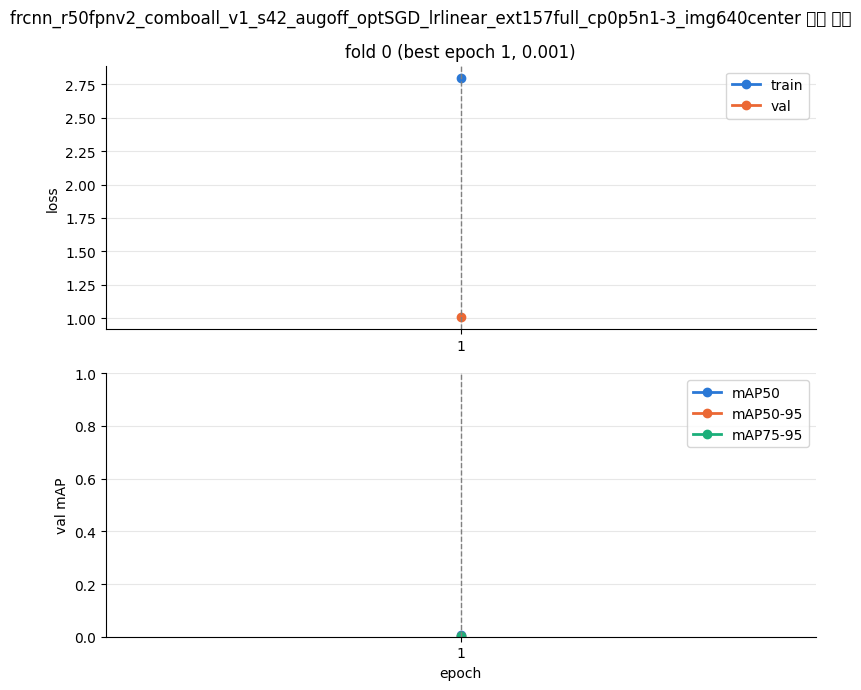

In [16]:
SMOKE_CFG = {
    **CFG,
    "exp": "frcnn_copy_paste_smoke",
    "folds": [0],
    "epochs": 1,
    "fraction": 0.1,
    "cos_lr": False,
}
smoke = run_folds(SMOKE_CFG, skip_done=False)
display(smoke.T)
plot_curves(SMOKE_CFG)

## 10. 본 학습

시간이 오래 걸리므로 `RUN_FULL = True`로 바꿔야 돈다. 끊겼다가 다시 돌리면 평가가 끝난 fold는 건너뛴다.

In [17]:
RUN_FULL = True
if RUN_FULL:
    full = run_folds(
        {
            **CFG,
            "folds": [0],
            "cos_lr": False,
        }
    )
    display(full.T)

OpenCV Copy-Paste: 확률 0.5, 객체 1~3개, train donor bbox 11,940개
[frcnn_r50fpnv2_comboall_v1_s42_augoff_optSGD_lrlinear_ext157full_cp0p5n1-3_img640center_fold0] train 195장 + 외부 4664장, val 1215장(외부 1178장 포함), device cuda


fold0 epoch 1:   0%|          | 0/304 [00:00<?, ?it/s]

/tmp/ipykernel_383/3811624042.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold0 val loss:   0%|          | 0/304 [00:00<?, ?it/s]

predict:   0%|          | 0/304 [00:00<?, ?it/s]

epoch   1  loss 1.8788  val_loss 0.9490  mAP75-95 0.0000  mAP50 0.0095  785s  *best
  시간: 학습 525.7s / 검증 손실 55.2s / 검증 예측·지표 204.4s


... (122 outputs left out)

predict:   0%|          | 0/304 [00:00<?, ?it/s]

epoch  32  loss 0.0329  val_loss 0.0309  mAP75-95 0.9661  mAP50 0.9861  787s  *best
  시간: 학습 528.4s / 검증 손실 55.2s / 검증 예측·지표 203.2s


fold0 epoch 33:   0%|          | 0/304 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [22]:
RUN_ALL_FOLDS = False
if RUN_ALL_FOLDS:
    full = run_folds(CFG)
    display(full.T)

## 11. 5 fold 요약

`models/evaluate.py`의 `summarize_exp`와 같은 방식으로 run별 평균·표준편차를 `summary.csv`에 저장한다.
같은 `results/` 폴더에 YOLO 결과가 있으면 한 표에 함께 나온다.

In [23]:
def summarize_exp(cfg: dict) -> pd.DataFrame:
    """results 폴더의 fold 요약을 run별 평균·표준편차로 모아 summary.csv에 저장한다."""
    out_dir = results_dir(cfg)
    runs = pd.concat(
        [pd.read_csv(p) for p in sorted(out_dir.glob("*_summary.csv"))], ignore_index=True
    )
    numeric = runs.drop(columns=["fold"]).select_dtypes("number").columns
    summary = runs.groupby("run")[list(numeric)].agg(["mean", "std"])
    summary.insert(0, ("n_folds", "count"), runs.groupby("run")["fold"].nunique())
    summary = summary.sort_values((MAIN_METRIC, "mean"), ascending=False)
    summary.to_csv(out_dir / "summary.csv", encoding="utf-8")
    return summary


REPORT_CFG = CFG if RUN_FULL or RUN_ALL_FOLDS else SMOKE_CFG
summarize_exp(REPORT_CFG)[[MAIN_METRIC, "map50", "map50_95", "precision", "recall"]]

ValueError: No objects to concatenate

## 12. 학습 곡선

fold별로 epoch마다 train·val 손실(위)과 val mAP50·mAP50-95·mAP75-95(아래)를 그린다.
점선은 mAP75-95가 가장 높은 epoch(`best.pt`)이다. 각 run의 `results.csv`를 읽으므로
학습이 끝난 뒤 커널을 다시 켜도 그릴 수 있다. 함수는 8절에 있다. val 손실을 기록하기 전에 학습한 run은 train 손실만 나온다.

/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:49: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
/tmp/ipykernel_383/2696786801.py:52: UserWarning: Glyph 44257 (\N{HANGUL 

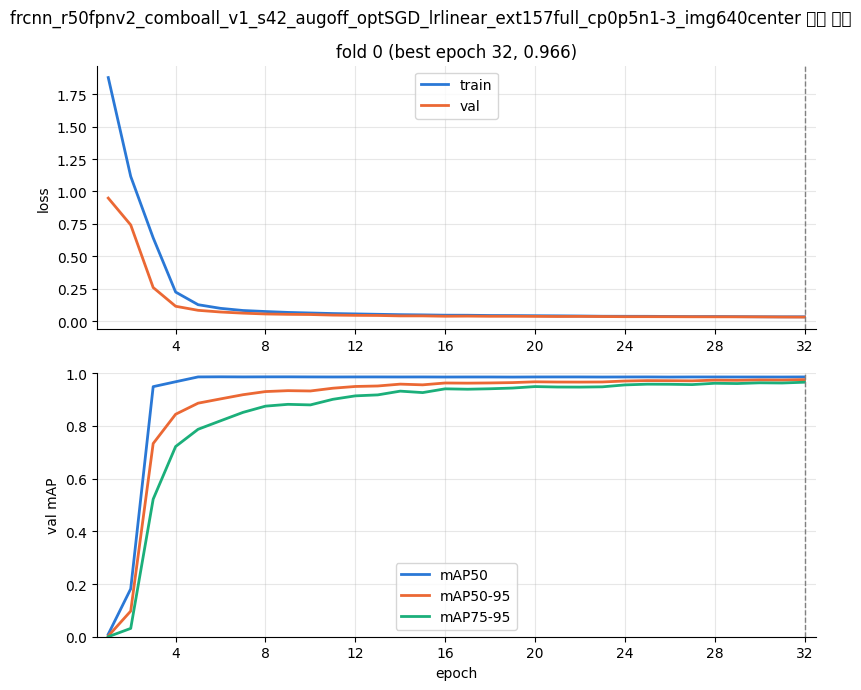

In [20]:
plot_curves(REPORT_CFG)

## 13. 혼동행렬

conf 0.001과 0.25에서 **원시 건수(로그 색상)**와 **정답 열 기준 비율(0~1)**을 각각 그린다.
큰 그림·칸별 수치·색상 범례를 사용하고, 두 신뢰도의 정규화 그림은 같은 색 범위로 비교한다.
행 = 예측, 열 = 정답이며 마지막 행은 미검출(FN), 마지막 열은 오검출(FP)이다.
배경 행에 값이 몰리면 해당 신뢰도·IoU에서 정답을 놓친 결과이며, 표시를 위해 값을 바꾸지 않는다.
한글 글꼴이 없는 Colab에서도 축이 깨지지 않도록 그림의 축 설명은 영어로 표시한다.

In [21]:
from matplotlib.colors import LogNorm

REPORT_FOLD = REPORT_CFG["folds"][0]


def load_val_pred(cfg: dict, fold: int) -> tuple[pd.DataFrame, pd.DataFrame, list[str]]:
    """evaluate_fold가 저장한 val 예측과 그 fold의 val 정답·사진 목록을 읽는다."""
    pred = pd.read_csv(
        results_dir(cfg) / f"{run_stem(cfg, fold)}_val_pred.csv",
        keep_default_na=False,
    )
    val_files = fold_files(fold, "val")
    return pred, LABELS[LABELS["file_name"].isin(val_files)], val_files


def plot_confusion(matrix: np.ndarray, title: str, ax: plt.Axes, normalize: bool = False) -> None:
    """배경까지 포함한 혼동행렬을 건수 또는 정답 열 기준 비율과 실제 수치로 그린다."""
    names = [*map(str, CLASS_MAP["category_id"]), "background"]
    if normalize:
        totals = matrix.sum(axis=0, keepdims=True)
        values = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals > 0)
        color_options = {"vmin": 0, "vmax": 1}
        legend = "Fraction within each true-label column"
        mode = "Normalized by true class"
    else:
        values = matrix.astype(float)
        color_options = {"norm": LogNorm(vmin=1, vmax=max(2, float(values.max())))}
        legend = "Number of objects (log color scale)"
        mode = "Object counts"
    colors = plt.get_cmap("Blues").copy()
    colors.set_bad("#f0f0f0")
    image = ax.imshow(
        np.ma.masked_where(values == 0, values),
        cmap=colors,
        interpolation="nearest",
        **color_options,
    )
    colorbar = ax.figure.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
    colorbar.set_label(legend, fontsize=11)
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_xlabel("True class | last column: background (false positives)", fontsize=12)
    ax.set_ylabel("Predicted class | last row: background (missed objects)", fontsize=12)
    boundary = len(names) - 1.5
    ax.axhline(boundary, color="#555555", linewidth=1.5)
    ax.axvline(boundary, color="#555555", linewidth=1.5)
    ax.get_xticklabels()[-1].set_fontweight("bold")
    ax.get_yticklabels()[-1].set_fontweight("bold")
    for row, column in np.argwhere(matrix > 0):
        value = values[row, column]
        label = (
            (f"{value:.0%}" if value >= 0.01 else "<1%")
            if normalize
            else f"{matrix[row, column]:.0f}"
        )
        ax.text(
            column,
            row,
            label,
            ha="center",
            va="center",
            fontsize=6,
            color="white" if image.norm(value) > 0.5 else "#111111",
        )
    matched = int(matrix[:-1, :-1].sum())
    missed = int(matrix[-1, :-1].sum())
    false_positives = int(matrix[:-1, -1].sum())
    ax.set_title(
        f"{title} | {mode}\n"
        f"Matched: {matched:,} | Missed (FN): {missed:,} | False positives: {false_positives:,}",
        fontsize=13,
        pad=14,
    )
    if not matrix.any():
        ax.text(
            0.5, 0.5, "No ground-truth objects or detections", transform=ax.transAxes, ha="center"
        )


val_pred, val_gt, val_files = load_val_pred(REPORT_CFG, REPORT_FOLD)
plot_dir = results_dir(REPORT_CFG) / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
for cm_conf in (0.001, 0.25):
    matrix = confusion_matrix(val_pred, val_gt, val_files, len(CLASS_MAP), cm_conf)
    for normalized in (False, True):
        fig, ax = plt.subplots(figsize=(16, 15), layout="constrained")
        plot_confusion(
            matrix,
            f"Fold {REPORT_FOLD} | conf > {cm_conf:g} | IoU > {CM_IOU:g}",
            ax,
            normalize=normalized,
        )
        suffix = "normalized" if normalized else "counts"
        plot_path = plot_dir / (
            f"{run_stem(REPORT_CFG, REPORT_FOLD)}_confusion_conf{cm_conf:g}_{suffix}.png"
        )
        fig.savefig(plot_path, dpi=220, bbox_inches="tight")
        print("혼동행렬 저장:", plot_path)
        plt.show()
        plt.close(fig)

FileNotFoundError: [Errno 2] No such file or directory: '/tmp/pill-bbox-data/runs/frcnn_copy_paste/results/frcnn_r50fpnv2_comboall_v1_s42_augoff_optSGD_lrlinear_ext157full_cp0p5n1-3_img640center_fold0_val_pred.csv'

## 14. 실패 사례

고정 기준(신뢰도 0.5 이상, IoU 0.5 이상 짝)으로 val 예측을 정답과 짝짓고 세 가지 실패를 그린다.

- 놓침: 짝이 없는 정답 (초록 점선)
- 다른 약: 짝은 지었지만 약이 틀림 (빨강)
- 위치 어긋남: 약은 맞지만 IoU < 0.75 (주황). 주 지표 mAP75-95에서 점수를 받지 못한다.

정답은 초록 실선, 짝이 없는 예측(오검출)은 보라 점선이다. 실패가 많은 사진부터 그린다.

In [ ]:
LOOSE_IOU = 0.75


def failure_table(pred: pd.DataFrame, gt: pd.DataFrame) -> pd.DataFrame:
    """정답마다 실패 종류(missed, wrong_class, loose_box, ok)와 짝지은 예측을 붙인 표."""
    pred = pred[pred["conf"] >= POINT_CONF]
    pairs = match_boxes(pred, gt).set_index("gt_row")
    table = gt.copy()
    table["pred_row"] = table.index.map(pairs["pred_row"])
    table["pred_category"] = table.index.map(pairs["pred_category"])
    table["iou"] = table.index.map(pairs["iou"])
    table["failure"] = np.select(
        [
            table["pred_row"].isna(),
            table["pred_category"] != table["category_id"],
            table["iou"] < LOOSE_IOU,
        ],
        ["missed", "wrong_class", "loose_box"],
        "ok",
    )
    return table


def plot_failures(
    pred: pd.DataFrame, gt: pd.DataFrame, n_images: int = 6, ncols: int = 3
) -> plt.Figure | None:
    """실패가 많은 사진 n_images장에 정답·예측 박스를 그린다."""
    table = failure_table(pred, gt)
    shown = pred[pred["conf"] >= POINT_CONF]
    unmatched = shown.drop(index=table["pred_row"].dropna().astype(int))
    n_fail = (table["failure"] != "ok").groupby(table["file_name"]).sum()
    n_fail = n_fail.add(unmatched["file_name"].value_counts(), fill_value=0)
    files = n_fail[n_fail > 0].sort_values(ascending=False).index[:n_images]
    if len(files) == 0:
        print("실패 사례가 없습니다.")
        return None
    print(table["failure"].value_counts().to_dict(), f"오검출 {len(unmatched)}개")
    nrows = math.ceil(len(files) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows), squeeze=False)
    colors = {"wrong_class": "red", "loose_box": "orange"}
    for ax, name in zip(axes.flat, files, strict=False):
        with Image.open(training_image_path(TRAIN_IMG_DIR, name)) as img:
            ax.imshow(img.convert("RGB"))
        for _, row in table[table["file_name"] == name].iterrows():
            style = "--" if row["failure"] == "missed" else "-"
            ax.add_patch(
                Rectangle((row.x, row.y), row.w, row.h, fill=False, ec="lime", lw=2, ls=style)
            )
            ax.text(row.x, row.y - 5, str(row.category_id), color="lime", fontsize=8)
            if row["failure"] in colors:
                p = shown.loc[int(row["pred_row"])]
                color = colors[row["failure"]]
                ax.add_patch(Rectangle((p.x, p.y), p.w, p.h, fill=False, ec=color, lw=2))
                ax.text(
                    p.x,
                    p.y + p.h + 25,
                    f"{p.category_id} {p.conf:.2f} IoU {row.iou:.2f}",
                    color=color,
                    fontsize=8,
                )
        for _, p in unmatched[unmatched["file_name"] == name].iterrows():
            ax.add_patch(Rectangle((p.x, p.y), p.w, p.h, fill=False, ec="violet", lw=2, ls=":"))
            ax.text(
                p.x, p.y + p.h + 25, f"{p.category_id} {p.conf:.2f}", color="violet", fontsize=8
            )
        ax.set_title(name, fontsize=8)
        ax.axis("off")
    for ax in list(axes.flat)[len(files) :]:
        ax.axis("off")
    fig.tight_layout()
    return fig


fig = plot_failures(val_pred, val_gt)
if fig is not None:
    fig.savefig(plot_dir / f"{run_stem(REPORT_CFG, REPORT_FOLD)}_failures.png", dpi=100)
    plt.show()

## 15. test 예측과 제출 csv

한 fold의 `best.pt`로 test 842장을 예측해 제출 형식
`annotation_id, image_id, category_id, bbox_x, bbox_y, bbox_w, bbox_h, score`로 저장한다.
`category_id`는 원본 JSON id, 좌표는 원본 픽셀 xywh, `image_id`는 파일 이름의 숫자다.
행은 image_id 순, 같은 사진 안에서는 score가 높은 순이고 conf 0.001 미만은 버린다.

In [ ]:
SUBMISSION_COLS = [
    "annotation_id",
    "image_id",
    "category_id",
    "bbox_x",
    "bbox_y",
    "bbox_w",
    "bbox_h",
    "score",
]


def to_submission(pred: pd.DataFrame) -> pd.DataFrame:
    """예측 표를 대회 제출 형식으로 바꾼다(models/evaluate.py의 to_submission과 같음)."""
    sub = pred.rename(
        columns={"x": "bbox_x", "y": "bbox_y", "w": "bbox_w", "h": "bbox_h", "conf": "score"}
    )
    sub["image_id"] = sub["file_name"].map(lambda name: int(Path(name).stem))
    sub = sub.sort_values(["image_id", "score"], ascending=[True, False], ignore_index=True)
    sub["annotation_id"] = sub.index + 1
    return sub[SUBMISSION_COLS]


def make_submission(cfg: dict, fold: int, device: str = DEVICE) -> tuple[pd.DataFrame, Path]:
    """fold의 best.pt로 test를 예측해 제출 csv를 저장하고 (제출 표, 경로)를 반환한다."""
    stem = run_stem(cfg, fold)
    weights = Path(cfg["runs_dir"]) / cfg["exp"] / stem / "weights" / "best.pt"
    model = load_model(weights, cfg, device)
    test_files = sorted(
        (p.name for p in TEST_IMG_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg"}),
        key=lambda name: int(Path(name).stem),
    )
    pred, _ = predict_images(model, TEST_IMG_DIR, test_files, device, cfg["eval_batch"], "test")
    pred = pred[pred["conf"] >= cfg["conf"]]
    out_dir = results_dir(cfg)
    pred.to_csv(out_dir / f"{stem}_test_pred.csv", index=False, encoding="utf-8")
    sub = to_submission(pred)
    out_path = out_dir / f"{stem}_submission_conf{cfg['conf']:g}.csv"
    sub.to_csv(out_path, index=False, encoding="utf-8")
    return sub, out_path


RUN_SUBMISSION = False
if RUN_SUBMISSION:
    sub, sub_path = make_submission(REPORT_CFG, REPORT_FOLD)
    print(f"사진 {sub['image_id'].nunique()}장, 박스 {len(sub)}개: {sub_path}")
    display(sub.head())

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator


def plot_local_training_history(csv_path: Path) -> None:
    """PC에 저장한 전체 에폭 기록으로 학습·검증 손실과 검증 지표를 그린다."""
    if not csv_path.is_file():
        raise FileNotFoundError(f"PC에 본 학습 results.csv를 복사해 주세요: {csv_path}")
    history = pd.read_csv(csv_path).sort_values("epoch")
    missing = sorted({"epoch", "map75_95"} - set(history.columns))
    if missing:
        raise ValueError(f"학습 기록에 필수 열이 없습니다: {missing}")
    if history.empty or history["map75_95"].notna().sum() == 0:
        raise ValueError("시각화할 에폭 또는 mAP75-95 기록이 없습니다.")

    best_row = history.loc[history["map75_95"].idxmax()]
    best_epoch = int(best_row["epoch"])
    marker = "o" if len(history) <= 15 else None
    loss_specs = [
        ("loss", "Total loss"),
        ("loss_classifier", "RoI classification loss"),
        ("loss_box_reg", "RoI box regression loss"),
        ("loss_objectness", "RPN objectness loss"),
        ("loss_rpn_box_reg", "RPN box regression loss"),
    ]
    # 최고 mAP75-95를 기록한 동일 에폭의 손실과 지표를 함께 출력한다.
    best_losses = pd.DataFrame(
        {
            label: {
                title: best_row.get(f"{split}/{key}", float("nan")) for key, title in loss_specs
            }
            for split, label in (("train", "Train"), ("val", "Validation"))
        }
    )
    best_metric_specs = [
        ("map75_95", "mAP75-95"),
        ("map50", "mAP50"),
        ("map75", "mAP75"),
        ("map50_95", "mAP50-95"),
        ("ul_precision", "Precision (macro, max-F1)"),
        ("ul_recall", "Recall (macro, max-F1)"),
    ]
    best_metrics = pd.DataFrame(
        {
            "Value": {
                title: best_row[key] for key, title in best_metric_specs if key in history.columns
            }
        }
    )
    print(f"{csv_path.parent.name} | 최고 mAP75-95 에폭: {best_epoch}")
    print("최고 에폭의 학습·검증 손실")
    display(best_losses.round(6))
    print("동일 에폭의 검증 평가지표")
    display(best_metrics.round(6))

    panels = [
        (title, [(f"train/{key}", "Train"), (f"val/{key}", "Validation")], False)
        for key, title in loss_specs
    ]
    panels += [
        ("Validation mAP75-95", [("map75_95", "mAP75-95")], True),
        (
            "Validation other mAP",
            [("map50", "mAP50"), ("map75", "mAP75"), ("map50_95", "mAP50-95")],
            True,
        ),
        ("Validation precision (macro, max-F1)", [("ul_precision", "Precision")], True),
        ("Validation recall (macro, max-F1)", [("ul_recall", "Recall")], True),
    ]

    nrows = math.ceil(len(panels) / 3)
    fig, axes = plt.subplots(nrows, 3, figsize=(18, 4 * nrows))
    for axis, (title, columns, is_metric) in zip(axes.flat, panels, strict=False):
        for column, label in columns:
            if column in history.columns:
                axis.plot(
                    history["epoch"],
                    history[column],
                    label=label,
                    marker=marker,
                    linewidth=1.8,
                )
        axis.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch {best_epoch}")
        axis.set(
            title=title,
            xlabel="Epoch",
            ylabel="Score" if is_metric else "Loss",
            xlim=(history["epoch"].min() - 0.5, history["epoch"].max() + 0.5),
        )
        if is_metric:
            axis.set_ylim(-0.02, 1.02)
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.grid(alpha=0.3)
        axis.legend(fontsize=8)

    for axis in list(axes.flat)[len(panels) :]:
        axis.axis("off")
    fig.suptitle(
        f"{csv_path.parent.name}\nBest epoch: {best_epoch} | mAP75-95: {best_row['map75_95']:.4f}"
    )
    fig.tight_layout()
    plt.show()
    plt.close(fig)


# 프로젝트 밖에서 실행한다면 저장소 경로를 직접 지정할 수 있다.
VISUALIZATION_PROJECT_ROOT: Path | None = None
LOCAL_PROJECT_ROOT = (
    Path(VISUALIZATION_PROJECT_ROOT).expanduser().resolve()
    if VISUALIZATION_PROJECT_ROOT is not None
    else PROJECT_ROOT
)
print(f"시각화 기준 경로: {LOCAL_PROJECT_ROOT}")

# 현재 설정의 결과 폴더를 우선 사용하며, PC 경로를 지정했다면 그 runs 폴더를 본다.
history_cfg = globals().get("REPORT_CFG", globals().get("CFG", {}))
history_runs = Path(history_cfg.get("runs_dir", LOCAL_PROJECT_ROOT / "runs"))
if VISUALIZATION_PROJECT_ROOT is not None:
    history_runs = LOCAL_PROJECT_ROOT / "runs"
LOCAL_HISTORY_ROOT = history_runs / history_cfg.get("exp", "frcnn_copy_paste")
LOCAL_HISTORY_PATHS = sorted(LOCAL_HISTORY_ROOT.glob("frcnn_r50fpnv2_*_fold*/results.csv"))
if not LOCAL_HISTORY_PATHS:
    print(f"학습 기록이 없어 추가 시각화를 건너뜁니다: {LOCAL_HISTORY_ROOT}")
for history_path in LOCAL_HISTORY_PATHS:
    plot_local_training_history(history_path)

In [ ]:
from pathlib import Path

import numpy as np

# 현재 본 학습 설정: 선형 감소, fold 0
submission_cfg = {**CFG, "cos_lr": False}
submission_fold = 0

# 파일 이름은 여기서 변경하면 된다.
output_path = RUNS_ROOT.parent / "submission_faster_rcnn_jang3.csv"

weights = (
    Path(submission_cfg["runs_dir"])
    / submission_cfg["exp"]
    / run_stem(submission_cfg, submission_fold)
    / "weights"
    / "best.pt"
)

if not weights.is_file():
    raise FileNotFoundError(f"학습된 가중치가 없습니다: {weights}")

if output_path.exists():
    raise FileExistsError(f"같은 파일이 있습니다. 출력 이름을 변경하세요: {output_path}")

# 기본 데이터와 외부 데이터를 함께 학습한 실험인지 확인한다.
config_path = weights.parent.parent / "config.json"
saved_config = json.loads(config_path.read_text(encoding="utf-8"))

if saved_config.get("n_external_train_images", 0) <= 0:
    raise ValueError("외부 데이터를 함께 학습한 모델인지 확인하세요.")

test_files = sorted(
    (
        path.name
        for path in TEST_IMG_DIR.iterdir()
        if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ),
    key=lambda name: int(Path(name).stem),
)

if not test_files:
    raise FileNotFoundError(f"test 이미지가 없습니다: {TEST_IMG_DIR}")

image_ids = [int(Path(name).stem) for name in test_files]
if len(image_ids) != len(set(image_ids)):
    raise ValueError("서로 다른 test 파일의 image_id가 중복됩니다.")

# 저장된 best.pt를 불러와 test 이미지만 예측한다.
print("사용 가중치:", weights)
print(
    f"학습 데이터: 기본 {saved_config['n_original_train_images']:,}장"
    f" + 외부 {saved_config['n_external_train_images']:,}장"
)

submission_model = load_model(weights, submission_cfg, DEVICE)
try:
    predictions, _ = predict_images(
        submission_model,
        TEST_IMG_DIR,
        test_files,
        DEVICE,
        submission_cfg["eval_batch"],
        "Kaggle test prediction",
    )
finally:
    del submission_model

# 기존 실험의 신뢰도 기준을 그대로 적용한다.
predictions = predictions.loc[predictions["conf"] >= submission_cfg["conf"]].copy()

if predictions.empty:
    raise ValueError("예측 객체가 없습니다. 가중치와 test 데이터를 확인하세요.")

# predict_images의 category_id는 원래 대회 약제 ID이다.
submission = predictions.rename(
    columns={
        "x": "bbox_x",
        "y": "bbox_y",
        "w": "bbox_w",
        "h": "bbox_h",
        "conf": "score",
    }
)
submission["image_id"] = submission["file_name"].map(lambda name: int(Path(name).stem))
submission["category_id"] = submission["category_id"].astype("int64")
submission = submission.sort_values(
    ["image_id", "score"],
    ascending=[True, False],
    ignore_index=True,
)

# 검출 객체 하나당 한 행, annotation_id는 전체 행에서 고유하게 지정한다.
submission["annotation_id"] = np.arange(1, len(submission) + 1)

submission_columns = [
    "annotation_id",
    "image_id",
    "category_id",
    "bbox_x",
    "bbox_y",
    "bbox_w",
    "bbox_h",
    "score",
]
submission = submission[submission_columns]

# bbox는 원본 이미지의 픽셀 단위 [x, y, width, height]이다.
numeric = submission.to_numpy(dtype=float)
if not np.isfinite(numeric).all():
    raise ValueError("제출 데이터에 결측 또는 무한대 값이 있습니다.")
if (
    submission[["bbox_x", "bbox_y"]].lt(0).any().any()
    or submission[["bbox_w", "bbox_h"]].le(0).any().any()
    or not submission["score"].between(0, 1).all()
):
    raise ValueError("bbox 좌표·크기 또는 score 범위가 잘못되었습니다.")

# 인덱스 열 없이 제출 CSV 하나만 저장한다.
submission.to_csv(output_path, index=False, encoding="utf-8")

print(f"제출 CSV: {output_path}")
print(
    f"test {len(test_files):,}장 / "
    f"검출된 이미지 {submission['image_id'].nunique():,}장 / "
    f"검출 객체 {len(submission):,}개"
)
display(submission.head())

In [ ]:
# 모든 결과는 STORAGE_ROOT 아래에 저장한다.
saved_experiments = [Path(CFG["runs_dir"]) / CFG["exp"]]
if "SMOKE_CFG" in globals():
    saved_experiments.append(Path(SMOKE_CFG["runs_dir"]) / SMOKE_CFG["exp"])

artifact_manifest = {
    "experiments": [str(path) for path in saved_experiments if path.is_dir()],
    "submission": str(output_path)
    if "output_path" in globals() and output_path.is_file()
    else None,
    "data_cache": str(LOCAL_DATA_DIR),
}
artifact_manifest_path = Path(CFG["runs_dir"]) / "jang3_artifacts.json"
artifact_manifest_path.parent.mkdir(parents=True, exist_ok=True)
artifact_manifest_path.write_text(
    json.dumps(artifact_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("결과 목록:", artifact_manifest_path)
print(json.dumps(artifact_manifest, ensure_ascii=False, indent=2))
print("결과도 /tmp의 임시 파일입니다. 세션 종료 전에 필요한 파일을 다운로드하세요.")
print("원본은 Kaggle Input에서 읽고 캐시·결과는 STORAGE_ROOT에 저장합니다.")

Confusion matrix prediction:   0%|          | 0/304 [00:00<?, ?it/s]

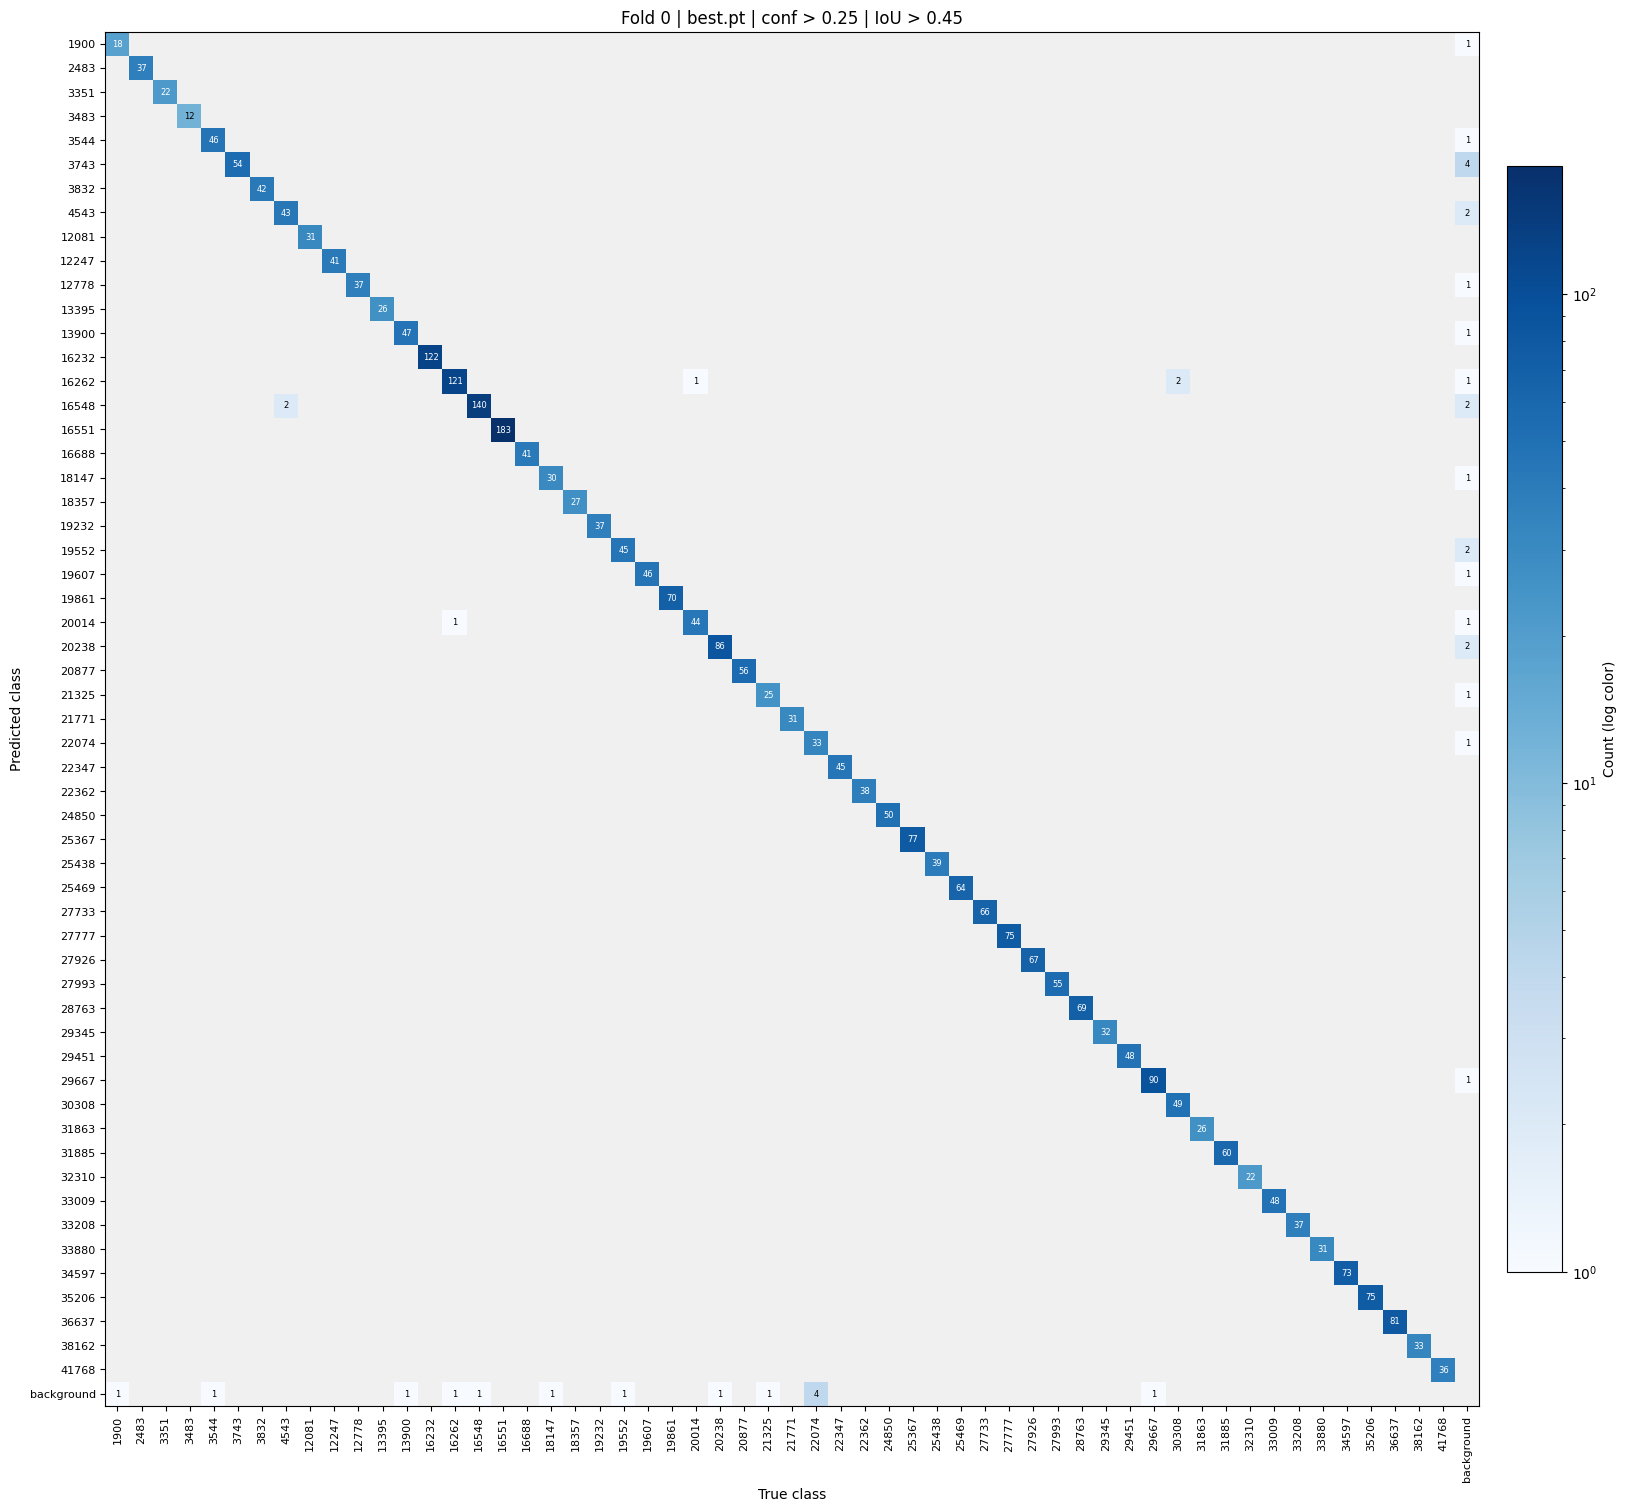

저장: /kaggle/working/confusion_fold0_conf0.25.png


In [24]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

FOLD = 0
CM_CONF = 0.25  # 0.001로 바꾸면 낮은 신뢰도의 예측까지 포함

# 중단한 본 학습: fold 0, 선형 학습률 감소
cm_cfg = {**CFG, "cos_lr": False}
cm_run_dir = Path(cm_cfg["runs_dir"]) / cm_cfg["exp"] / run_stem(cm_cfg, FOLD)
cm_weights = cm_run_dir / "weights" / "best.pt"
if not cm_weights.is_file():
    raise FileNotFoundError(f"가중치가 없습니다: {cm_weights}")

# 실제 학습 때 저장한 설정 사용
cm_cfg = json.loads((cm_run_dir / "config.json").read_text(encoding="utf-8"))
cm_files = fold_files(FOLD, "val")
cm_gt = LABELS[LABELS["file_name"].isin(cm_files)]

cm_model = load_model(cm_weights, cm_cfg, DEVICE)
try:
    cm_pred, _ = predict_images(
        cm_model,
        TRAIN_IMG_DIR,
        cm_files,
        DEVICE,
        cm_cfg["eval_batch"],
        "Confusion matrix prediction",
    )
finally:
    del cm_model

cm_matrix = confusion_matrix(cm_pred, cm_gt, cm_files, len(CLASS_MAP), CM_CONF)
cm_names = [*CLASS_MAP["category_id"].astype(str), "background"]

fig, ax = plt.subplots(figsize=(16, 15), layout="constrained")
cm_colors = plt.get_cmap("Blues").copy()
cm_colors.set_bad("#f0f0f0")
cm_image = ax.imshow(
    np.ma.masked_where(cm_matrix == 0, cm_matrix),
    cmap=cm_colors,
    norm=LogNorm(vmin=1, vmax=max(2, float(cm_matrix.max()))),
)
fig.colorbar(cm_image, ax=ax, fraction=0.04, pad=0.02, label="Count (log color)")
ax.set_xticks(range(len(cm_names)), cm_names, rotation=90, fontsize=8)
ax.set_yticks(range(len(cm_names)), cm_names, fontsize=8)
ax.set_xlabel("True class")
ax.set_ylabel("Predicted class")
ax.set_title(f"Fold {FOLD} | best.pt | conf > {CM_CONF} | IoU > 0.45")

for row, col in np.argwhere(cm_matrix > 0):
    value = cm_matrix[row, col]
    ax.text(
        col,
        row,
        f"{value:.0f}",
        ha="center",
        va="center",
        fontsize=6,
        color="white" if cm_image.norm(value) > 0.5 else "black",
    )

cm_output = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else cm_run_dir
cm_path = cm_output / f"confusion_fold{FOLD}_conf{CM_CONF:g}.png"
fig.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("저장:", cm_path)

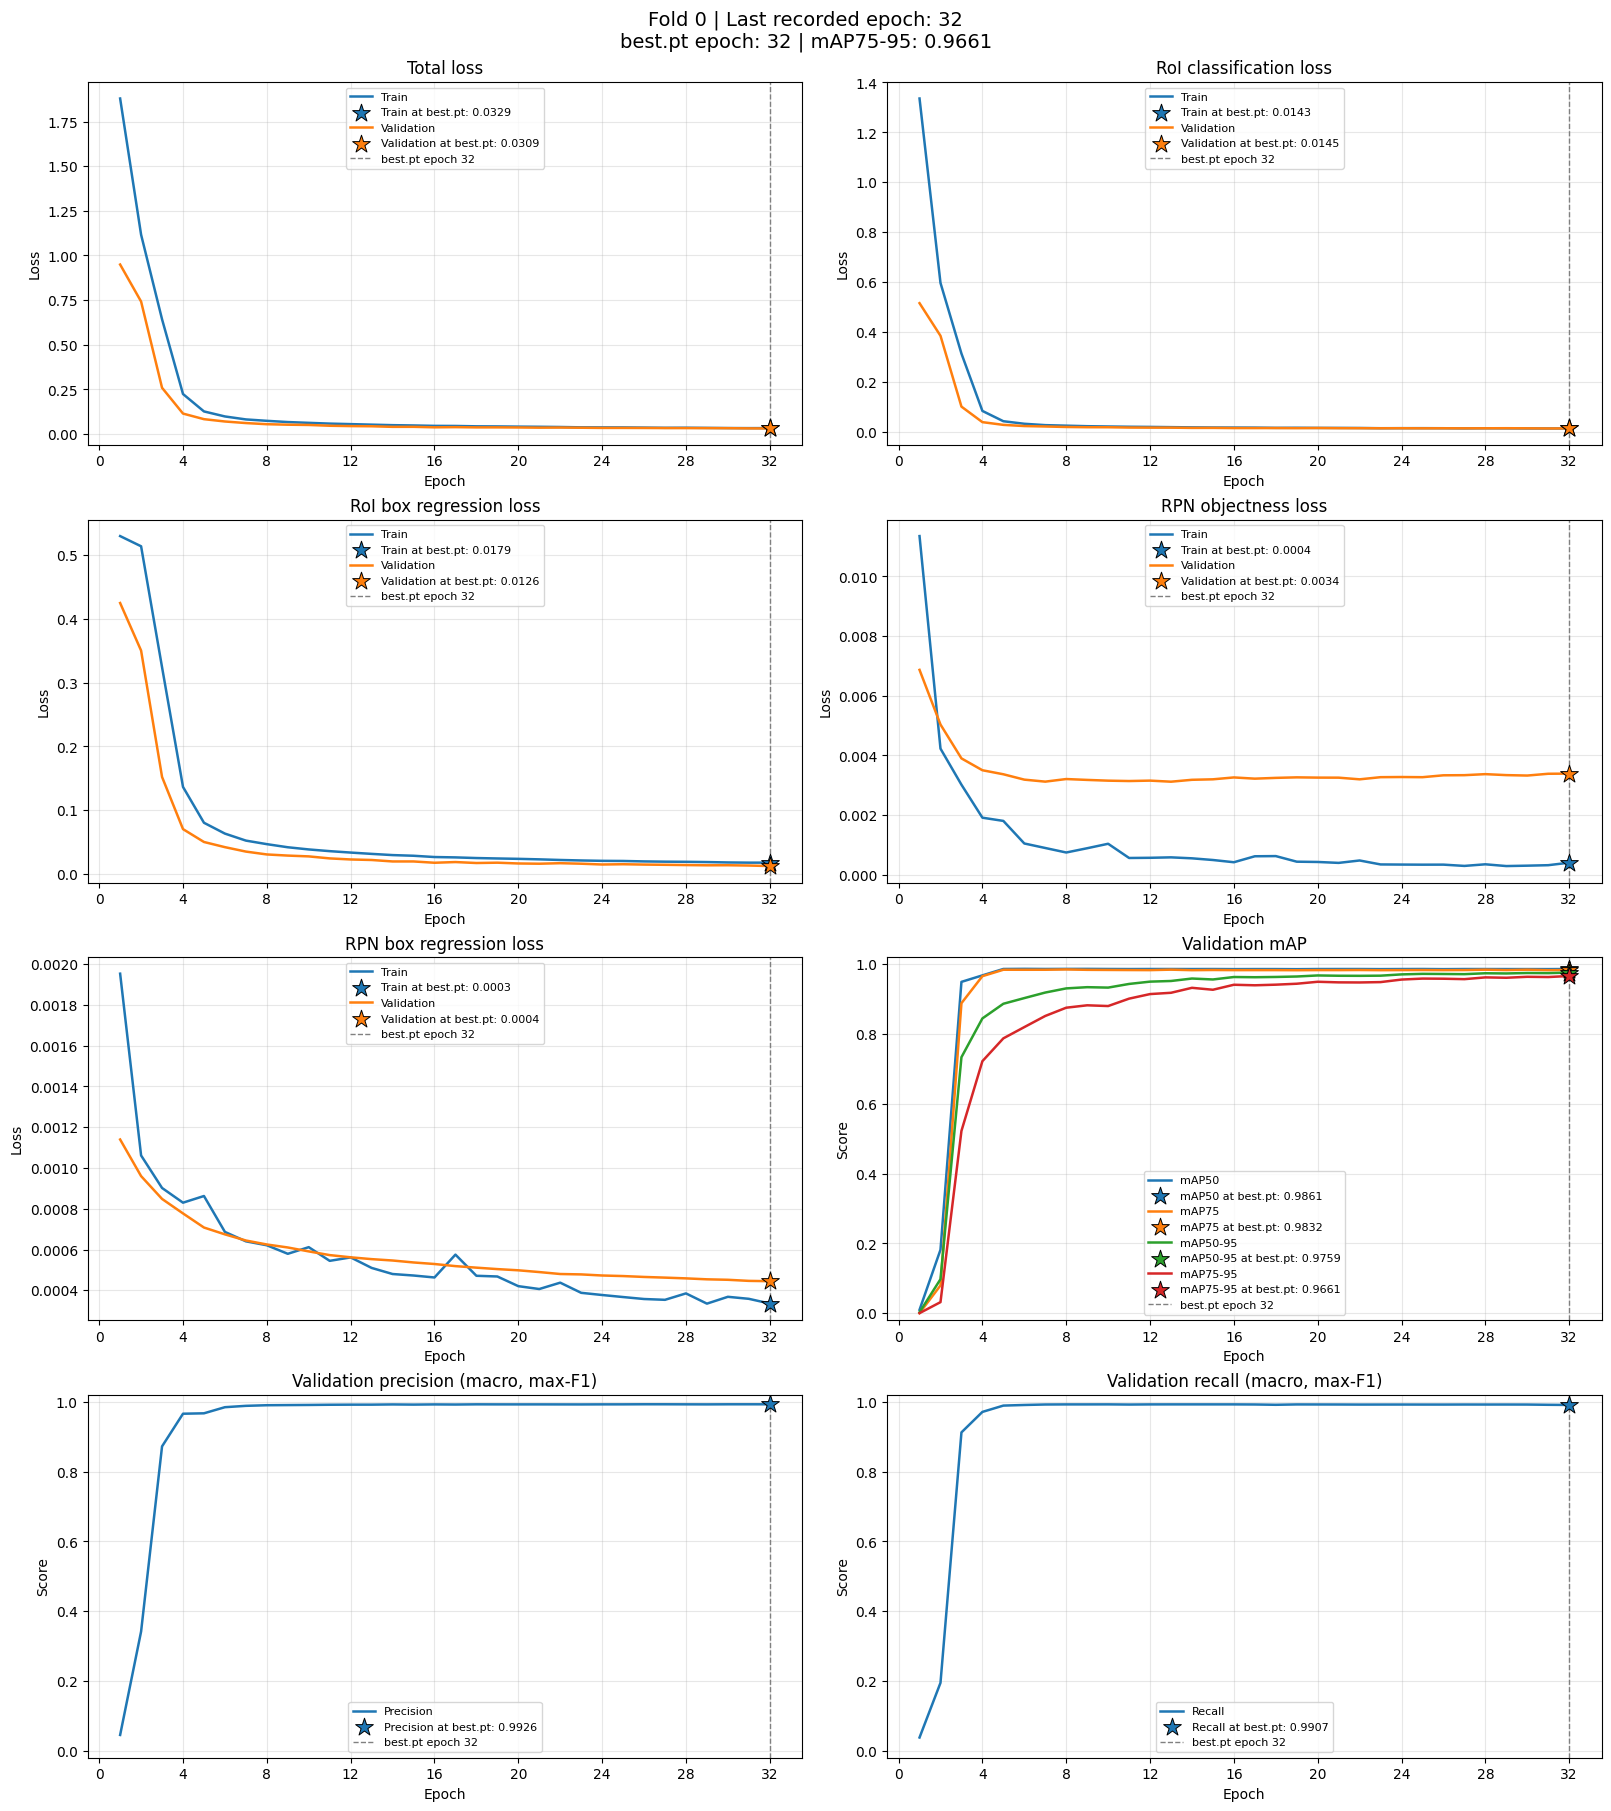

사용한 best.pt: /tmp/pill-bbox-data/runs/frcnn_copy_paste/frcnn_r50fpnv2_comboall_v1_s42_augoff_optSGD_lrlinear_ext157full_cp0p5n1-3_img640center_fold0/weights/best.pt
마지막 기록 epoch: 32
best.pt epoch: 32
그래프 저장: /kaggle/working/training_curves_with_best_pt_fold0.png


In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib.ticker import MaxNLocator

GRAPH_FOLD = 0
graph_cfg = {**CFG, "cos_lr": False}
graph_run_dir = Path(graph_cfg["runs_dir"]) / graph_cfg["exp"] / run_stem(graph_cfg, GRAPH_FOLD)
graph_csv = graph_run_dir / "results.csv"
graph_weights = graph_run_dir / "weights" / "best.pt"

for graph_file in (graph_csv, graph_weights):
    if not graph_file.is_file():
        raise FileNotFoundError(f"파일이 없습니다: {graph_file}")

# 중단 전 저장된 전체 학습 기록
graph_history = pd.read_csv(graph_csv).sort_values("epoch")
if graph_history.empty:
    raise ValueError("저장된 학습 기록이 없습니다.")

# CSV에서 최고점을 다시 고르지 않고 실제 best.pt의 epoch와 지표를 읽는다.
graph_checkpoint = torch.load(graph_weights, map_location="cpu", weights_only=False)
graph_best_epoch = int(graph_checkpoint["epoch"])
graph_best_metrics = dict(graph_checkpoint["metrics"])
del graph_checkpoint

graph_best_rows = graph_history[graph_history["epoch"] == graph_best_epoch]
if graph_best_rows.empty:
    raise ValueError(
        f"best.pt의 epoch {graph_best_epoch}가 results.csv에 없습니다. "
        "같은 실험의 파일인지 확인하세요."
    )

# 체크포인트에 없는 항목만 동일 epoch의 CSV 기록으로 보완한다.
graph_best_values = {
    **graph_best_rows.iloc[0].to_dict(),
    **graph_best_metrics,
}

graph_loss_specs = [
    ("loss", "Total loss"),
    ("loss_classifier", "RoI classification loss"),
    ("loss_box_reg", "RoI box regression loss"),
    ("loss_objectness", "RPN objectness loss"),
    ("loss_rpn_box_reg", "RPN box regression loss"),
]
graph_panels = [
    (
        title,
        [(f"train/{key}", "Train"), (f"val/{key}", "Validation")],
        False,
    )
    for key, title in graph_loss_specs
]
graph_panels += [
    (
        "Validation mAP",
        [
            ("map50", "mAP50"),
            ("map75", "mAP75"),
            ("map50_95", "mAP50-95"),
            ("map75_95", "mAP75-95"),
        ],
        True,
    ),
    (
        "Validation precision (macro, max-F1)",
        [("ul_precision", "Precision")],
        True,
    ),
    (
        "Validation recall (macro, max-F1)",
        [("ul_recall", "Recall")],
        True,
    ),
]

graph_fig, graph_axes = plt.subplots(4, 2, figsize=(16, 18), layout="constrained")

for graph_ax, (title, columns, is_metric) in zip(graph_axes.flat, graph_panels, strict=True):
    graph_drawn = False
    for column, label in columns:
        if column not in graph_history or not graph_history[column].notna().any():
            continue

        (graph_line,) = graph_ax.plot(
            graph_history["epoch"],
            graph_history[column],
            label=label,
            linewidth=1.8,
            marker="o" if len(graph_history) <= 30 else None,
            markersize=3,
        )
        graph_drawn = True

        # 실제 best.pt에 대응하는 동일 epoch의 값을 별표로 표시
        graph_value = graph_best_values.get(column)
        if graph_value is not None and pd.notna(graph_value):
            graph_ax.scatter(
                graph_best_epoch,
                graph_value,
                marker="*",
                s=180,
                color=graph_line.get_color(),
                edgecolors="black",
                linewidths=0.7,
                zorder=5,
                label=f"{label} at best.pt: {graph_value:.4f}",
            )

    graph_ax.axvline(
        graph_best_epoch,
        color="gray",
        linestyle="--",
        linewidth=1,
        label=f"best.pt epoch {graph_best_epoch}",
    )
    if not graph_drawn:
        graph_ax.text(
            0.5,
            0.5,
            "No recorded values",
            transform=graph_ax.transAxes,
            ha="center",
            va="center",
        )

    graph_ax.set_title(title)
    graph_ax.set_xlabel("Epoch")
    graph_ax.set_ylabel("Score" if is_metric else "Loss")
    graph_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    graph_ax.grid(alpha=0.3)
    if is_metric:
        graph_ax.set_ylim(-0.02, 1.02)
    graph_ax.legend(fontsize=8)

graph_last_epoch = int(graph_history["epoch"].max())
graph_best_score = graph_best_values.get("map75_95", float("nan"))
graph_fig.suptitle(
    f"Fold {GRAPH_FOLD} | Last recorded epoch: {graph_last_epoch}\n"
    f"best.pt epoch: {graph_best_epoch} | mAP75-95: {graph_best_score:.4f}",
    fontsize=14,
)

graph_output_dir = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else graph_run_dir
graph_output_path = graph_output_dir / f"training_curves_with_best_pt_fold{GRAPH_FOLD}.png"
graph_fig.savefig(graph_output_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(graph_fig)

print("사용한 best.pt:", graph_weights)
print("마지막 기록 epoch:", graph_last_epoch)
print("best.pt epoch:", graph_best_epoch)
print("그래프 저장:", graph_output_path)

In [27]:
from IPython.display import display

# 1. best.pt가 저장된 epoch의 학습·검증 손실
best_loss_table = pd.DataFrame(
    [
        {
            "손실": title,
            "Train": graph_best_values.get(f"train/{key}", float("nan")),
            "Validation": graph_best_values.get(f"val/{key}", float("nan")),
        }
        for key, title in graph_loss_specs
    ]
).set_index("손실")

# 2. 같은 best.pt epoch의 검증 평가지표
best_metric_table = pd.DataFrame(
    [
        {
            "평가지표": label,
            "Validation": graph_best_values.get(column, float("nan")),
        }
        for _, columns, _ in graph_panels[5:]
        for column, label in columns
    ]
).set_index("평가지표")

print(f"best.pt — epoch {graph_best_epoch}")
display(best_loss_table.round(6))
display(best_metric_table.round(6))

# 3. 중단 전 완료된 전체 epoch 기록
print(f"전체 학습 기록 — 마지막 epoch {graph_last_epoch}")
display(graph_history.round(6))

# 표를 CSV 파일로도 저장
best_loss_table.to_csv(
    graph_output_dir / f"best_pt_losses_fold{GRAPH_FOLD}.csv",
    encoding="utf-8-sig",
)
best_metric_table.to_csv(
    graph_output_dir / f"best_pt_metrics_fold{GRAPH_FOLD}.csv",
    encoding="utf-8-sig",
)
graph_history.to_csv(
    graph_output_dir / f"epoch_history_fold{GRAPH_FOLD}.csv",
    index=False,
    encoding="utf-8-sig",
)

print("표 저장 위치:", graph_output_dir)

best.pt — epoch 32


,Train,Validation
손실,,
Total loss,0.032932,0.030917
RoI classification loss,0.014292,0.014524
RoI box regression loss,0.017899,0.012558
RPN objectness loss,0.000406,0.003391
RPN box regression loss,0.000335,0.000445


,Validation
평가지표,
mAP50,0.986098
mAP75,0.983206
mAP50-95,0.975887
mAP75-95,0.966063
Precision,0.992623
Recall,0.990731


전체 학습 기록 — 마지막 epoch 32


,epoch,train/loss_classifier,train/loss_box_reg,train/loss_objectness,train/loss_rpn_box_reg,train/loss,val/loss_classifier,val/loss_box_reg,val/loss_objectness,val/loss_rpn_box_reg,...,map75_95,map50,map75,map50_95,ul_precision,ul_recall,time_s,train_time_s,val_loss_time_s,val_prediction_metric_time_s
0,1,1.335639,0.529860,0.011350,0.001953,1.878802,0.516071,0.424948,0.006867,0.001140,...,0.000046,0.009544,0.000230,0.002582,0.045224,0.037907,785.305783,525.698783,55.163568,204.443352
1,2,0.597042,0.513874,0.004229,0.001061,1.116206,0.385415,0.350371,0.005036,0.000960,...,0.031561,0.181681,0.079424,0.097334,0.341572,0.194605,780.511494,523.172704,54.256144,203.082185
2,3,0.314168,0.324262,0.003020,0.000902,0.642351,0.101782,0.152273,0.003901,0.000848,...,0.522193,0.949208,0.888119,0.733324,0.872052,0.912133,781.254034,524.826545,54.723594,201.703448
3,4,0.084513,0.136619,0.001914,0.000830,0.223877,0.039605,0.070469,0.003504,0.000777,...,0.721997,0.967817,0.965523,0.844473,0.965640,0.970838,787.977522,527.072636,56.845125,204.059285
4,5,0.043259,0.080436,0.001806,0.000862,0.126363,0.028686,0.050294,0.003369,0.000708,...,0.787404,0.986172,0.983964,0.886491,0.966828,0.988935,784.371344,526.403605,55.429008,202.538370
5,6,0.033068,0.063443,0.001050,0.000686,0.098247,0.023959,0.042189,0.003189,0.000674,...,0.819620,0.986547,0.983909,0.902739,0.984350,0.990702,783.573019,526.804193,55.176774,201.591571
6,7,0.027614,0.052472,0.000899,0.000640,0.081625,0.022235,0.035247,0.003122,0.000644,...,0.851555,0.986167,0.983934,0.918643,0.988222,0.992065,782.253649,525.967450,54.850902,201.434846
7,8,0.025474,0.046901,0.000748,0.000621,0.073743,0.020227,0.030757,0.003209,0.000625,...,0.875210,0.986385,0.984836,0.930524,0.989968,0.992328,787.549465,529.817554,55.585528,202.145910
8,9,0.023362,0.042026,0.000891,0.000579,0.066858,0.019290,0.028977,0.003180,0.000610,...,0.882082,0.986448,0.983710,0.934012,0.990383,0.992328,784.234449,526.435817,55.396622,202.401539
9,10,0.022182,0.038610,0.001040,0.000612,0.062444,0.019146,0.027709,0.003155,0.000591,...,0.879959,0.986132,0.983399,0.932790,0.990780,0.992422,785.816829,527.922806,55.381779,202.511910


표 저장 위치: /kaggle/working


In [29]:
best_epoch_table = pd.DataFrame(
    [
        {
            "epoch": graph_best_epoch,
            "mAP75-95": graph_best_values.get("map75_95"),
            "mAP50": graph_best_values.get("map50"),
            "mAP75": graph_best_values.get("map75"),
            "mAP50-95": graph_best_values.get("map50_95"),
            "Precision": graph_best_values.get("ul_precision"),
            "Recall": graph_best_values.get("ul_recall"),
            "Train loss": graph_best_values.get("train/loss"),
            "Val loss": graph_best_values.get("val/loss"),
        }
    ]
)

display(best_epoch_table.round(6))

,epoch,mAP75-95,mAP50,mAP75,mAP50-95,Precision,Recall,Train loss,Val loss
0,32,0.966063,0.986098,0.983206,0.975887,0.992623,0.990731,0.032932,0.030917
